<>:190: SyntaxWarning: invalid escape sequence '\p'
<>:190: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_5193/2777914125.py:190: SyntaxWarning: invalid escape sequence '\p'
  plt.title("Avoided crossing near $\phi_c$")


Q1 initial: w1=6.1690 GHz, alpha1=-192.5 MHz
Q2: w2=5.5053 GHz, alpha2=-203.4 MHz, g=10.0 MHz
CPHASE Flux: 0.1720


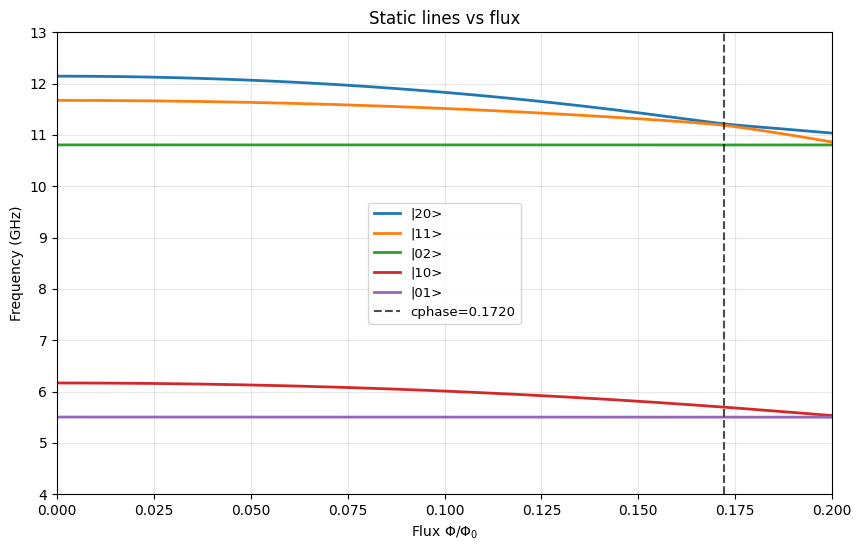

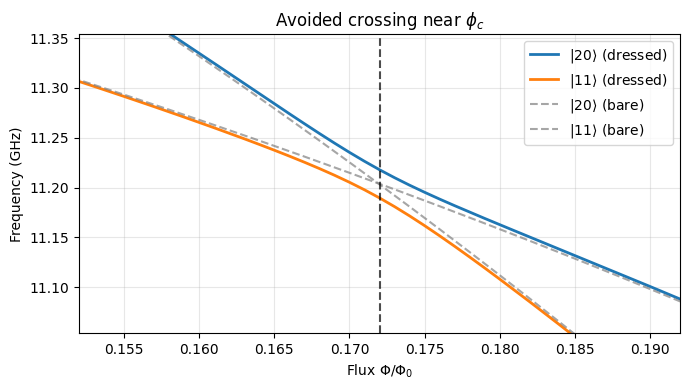

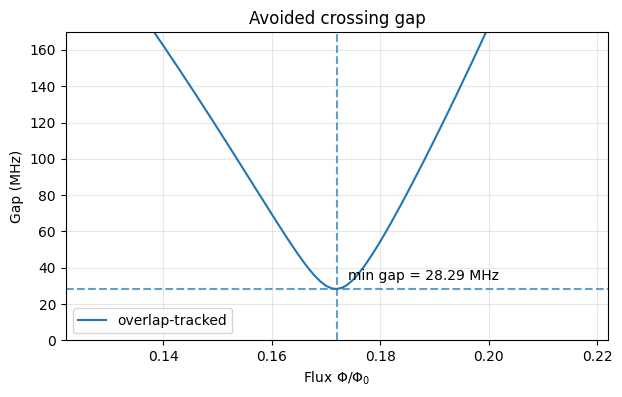

Min adiabatic gap = 28.286 MHz at flux = 0.1720
Q1 at flux_cphase (0.1720): w1=5.6985 GHz, alpha1=-193.8 MHz
Resonance condition check: w1+alpha1 = 5.5048 GHz, w2 = 5.5053 GHz
|11>-|20> bare detuning at cphase: 0.55 MHz


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la
from scipy.interpolate import interp1d
from scipy.optimize import minimize_scalar
import qutip as qt
import scqubits as scq

#define devices
q1 = scq.TunableTransmon(EJmax=28.13, EC=0.1794, d=0.0, ng=0.0, flux=0.0, ncut=15)
q2 = scq.Transmon(EJ=21.7, EC=0.1871, ng=0.0, ncut=12)

#q1 and q2 initials
spec1 = q1.eigenvals(evals_count=4)
w1_0 = float(spec1[1] - spec1[0]) # GHz
alpha1_0 = float((spec1[2] - spec1[1]) - (spec1[1] - spec1[0])) #GHz
print(f"Q1 initial: w1={w1_0:.4f} GHz, alpha1={alpha1_0*1000:.1f} MHz")

spec2 = q2.eigenvals(evals_count=4)
w2 = float(spec2[1] - spec2[0]) #GHz
alpha2 = float((spec2[2] - spec2[1]) - (spec2[1] - spec2[0])) #GHz

g_val = 0.01 #10 MHz
print(f"Q2: w2={w2:.4f} GHz, alpha2={alpha2*1000:.1f} MHz, g={g_val*1000:.1f} MHz")


#lookup tables for w1, α1
flux_lookup = np.linspace(0.0, 0.40, 401)
w1_vals, a1_vals = [], []
for f in flux_lookup:
    q1.flux = float(f)
    spec = q1.eigenvals(evals_count=4)
    w1_vals.append(float(spec[1] - spec[0]))
    a1_vals.append(float((spec[2] - spec[1]) - (spec[1] - spec[0])))

w1_interp = interp1d(flux_lookup, w1_vals, kind="cubic", fill_value="extrapolate")
a1_interp = interp1d(flux_lookup, a1_vals, kind="cubic", fill_value="extrapolate")


#qutip Duffing model
N = 4
dim = N*N

a = qt.destroy(N)
I = qt.qeye(N)
I_full = qt.tensor(I, I)

a1 = qt.tensor(a, I)
a2 = qt.tensor(I, a)
n1 = a1.dag() * a1
n2 = a2.dag() * a2

kerr1 = n1 * (n1 - I_full)
kerr2 = n2 * (n2 - I_full)

H2 = 2*np.pi * (w2 * n2 + 0.5 * alpha2 * kerr2)
Hint = 2*np.pi * (g_val * (a1.dag()*a2 + a1*a2.dag()))

def H_static(phi):
    w1 = float(w1_interp(float(phi)))
    a1v = float(a1_interp(float(phi)))
    H1 = 2*np.pi * (w1 * n1 + 0.5 * a1v * kerr1)
    return H1 + H2 + Hint


#identify branches + compute gaps
def idx(n1_level, n2_level):
    return n1_level*N + n2_level

ket11_np = np.zeros(dim, dtype=complex); ket11_np[idx(1,1)] = 1.0
ket20_np = np.zeros(dim, dtype=complex); ket20_np[idx(2,0)] = 1.0
ket02_np = np.zeros(dim, dtype=complex); ket02_np[idx(0,2)] = 1.0
ket10_np = np.zeros(dim, dtype=complex); ket10_np[idx(1,0)] = 1.0
ket01_np = np.zeros(dim, dtype=complex); ket01_np[idx(0,1)] = 1.0

flux_scan = np.linspace(0, 0.40, 401)

#gaps
gaps_adiabatic = [] #gap between fixed adiabatic branches labeled at phi=0
gaps_overlap = []  #gap between overlap-tracked |20> and |11> at each flux !!

#energies for plot spectrum
E_20 = []
E_11 = []
E_02 = []
E_10 = []
E_01 = []

#fixed branch indices (set once at phi=0)
fixed_idx_20 = fixed_idx_11 = fixed_idx_02 = fixed_idx_10 = fixed_idx_01 = None

for phi in flux_scan:
    H = H_static(phi).full()
    evals, evecs = la.eigh(H)

    o11 = np.abs(evecs.conj().T @ ket11_np)**2
    o20 = np.abs(evecs.conj().T @ ket20_np)**2
    o02 = np.abs(evecs.conj().T @ ket02_np)**2
    o10 = np.abs(evecs.conj().T @ ket10_np)**2
    o01 = np.abs(evecs.conj().T @ ket01_np)**2

    i11_tr = int(np.argmax(o11))
    i20_tr = int(np.argmax(o20))

    #overlap-tracked gap (for picking cphase)
    gaps_overlap.append(abs(evals[i20_tr] - evals[i11_tr]))

    #we set fixed indices once (at first phi)
    if fixed_idx_20 is None:
        overlaps = {"20": o20, "11": o11, "02": o02, "10": o10, "01": o01}
        chosen = set()
        fixed = {}

        for key in ["20", "11", "02", "10", "01"]:
            candidates = np.argsort(overlaps[key])[::-1]
            for k in candidates:
                if int(k) not in chosen:
                    fixed[key] = int(k)
                    chosen.add(int(k))
                    break

        fixed_idx_20 = fixed["20"]
        fixed_idx_11 = fixed["11"]
        fixed_idx_02 = fixed["02"]
        fixed_idx_10 = fixed["10"]
        fixed_idx_01 = fixed["01"]

    #store energies of fixed adiabatic branches
    E_20.append(evals[fixed_idx_20])
    E_11.append(evals[fixed_idx_11])
    E_02.append(evals[fixed_idx_02])
    E_10.append(evals[fixed_idx_10])
    E_01.append(evals[fixed_idx_01])

    #adiabatic gap between the fixed branches
    gaps_adiabatic.append(abs(evals[fixed_idx_20] - evals[fixed_idx_11])) #rad/ns

gaps_adiabatic = np.array(gaps_adiabatic)
gaps_overlap = np.array(gaps_overlap)

# choose cphase based on overlap-tracked |11>-|20| gap
idx_cphase = int(np.argmin(gaps_overlap))
flux_cphase = float(flux_scan[idx_cphase])

print(f"CPHASE Flux: {flux_cphase:.4f}")


#plot static spectrum (adiabatic branches!)
E_20 = np.array(E_20)
E_11 = np.array(E_11)
E_02 = np.array(E_02)
E_10 = np.array(E_10)
E_01 = np.array(E_01)

plt.figure(figsize=(10,6))

plt.plot(flux_scan, E_20/(2*np.pi), lw=2, label="|20>")
plt.plot(flux_scan, E_11/(2*np.pi), lw=2, label="|11>")
plt.plot(flux_scan, E_02/(2*np.pi), lw=2, label="|02>")
plt.plot(flux_scan, E_10/(2*np.pi), lw=2, label="|10>")
plt.plot(flux_scan, E_01/(2*np.pi), lw=2, label="|01>")

plt.axvline(flux_cphase, color="k", ls="--", alpha=0.7, label=f"cphase={flux_cphase:.4f}")
plt.xlabel(r"Flux $\Phi/\Phi_0$")
plt.xlim(0, 0.20)
plt.ylabel("Frequency (GHz)")
plt.ylim(4, 13)
plt.title("Static lines vs flux")
plt.grid(alpha=0.3)
plt.legend(loc="center", prop={'size': 9.5})
plt.show()


#bare (uncoupled) energies
E_11_bare = np.array([2*np.pi*(float(w1_interp(ph)) + w2) for ph in flux_scan])
E_20_bare = np.array([2*np.pi*(2*float(w1_interp(ph)) + float(a1_interp(ph))) for ph in flux_scan])

# plot zoom
plt.figure(figsize=(7, 4))
plt.plot(flux_scan, E_20/(2*np.pi), lw=2, label=r"$|20\rangle$ (dressed)")
plt.plot(flux_scan, E_11/(2*np.pi), lw=2, label=r"$|11\rangle$ (dressed)")
plt.plot(flux_scan, E_20_bare/(2*np.pi), lw=1.5, ls="--", color="gray", alpha=0.7, label=r"$|20\rangle$ (bare)")
plt.plot(flux_scan, E_11_bare/(2*np.pi), lw=1.5, ls="--", color="gray", alpha=0.7, label=r"$|11\rangle$ (bare)")
plt.axvline(flux_cphase, color="k", ls="--", alpha=0.7)
plt.xlabel(r"Flux $\Phi/\Phi_0$")
plt.ylabel("Frequency (GHz)")
plt.xlim(flux_cphase - 0.02, flux_cphase + 0.02)
y_center = 0.5*((E_11[idx_cphase] + E_20[idx_cphase])/(2*np.pi))
plt.ylim(y_center - 0.15, y_center + 0.15)
plt.title("Avoided crossing near $\phi_c$")
plt.grid(alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
#plt.savefig("avoided_crossing_zoom.pdf", dpi=150)
plt.show()


#gap plot (adiabatic)
gap_mhz = gaps_overlap/(2*np.pi)*1000.0
min_gap_mhz = float(np.min(gap_mhz))
min_gap_flux = float(flux_scan[int(np.argmin(gaps_overlap))])

plt.figure(figsize=(7,4))
plt.plot(flux_scan, gap_mhz, label="overlap-tracked")

#vertical line at cphase
plt.axvline(flux_cphase, ls="--", alpha=0.7)

#horizontal line at min gap value
plt.axhline(min_gap_mhz, ls="--", alpha=0.7)

#annotate min gap value
plt.text(flux_cphase + 0.002, min_gap_mhz + 5,
         f"min gap = {min_gap_mhz:.2f} MHz",
         fontsize=10)

plt.xlabel(r"Flux $\Phi/\Phi_0$")
plt.xlim(flux_cphase - 0.05, flux_cphase + 0.05)
plt.ylabel("Gap (MHz)")
plt.ylim(0, max(50, min_gap_mhz*6)) #auto-ish
plt.title("Avoided crossing gap")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print(f"Min adiabatic gap = {min_gap_mhz:.3f} MHz at flux = {min_gap_flux:.4f}")


#frequency of q1 at the cphase flux point
w1_at_cphase = float(w1_interp(flux_cphase))
alpha1_at_cphase = float(a1_interp(flux_cphase))
print(f"Q1 at flux_cphase ({flux_cphase:.4f}): w1={w1_at_cphase:.4f} GHz, alpha1={alpha1_at_cphase*1000:.1f} MHz")
print(f"Resonance condition check: w1+alpha1 = {(w1_at_cphase+alpha1_at_cphase):.4f} GHz, w2 = {w2:.4f} GHz")
print(f"|11>-|20> bare detuning at cphase: {abs(w1_at_cphase+alpha1_at_cphase-w2)*1000:.2f} MHz")

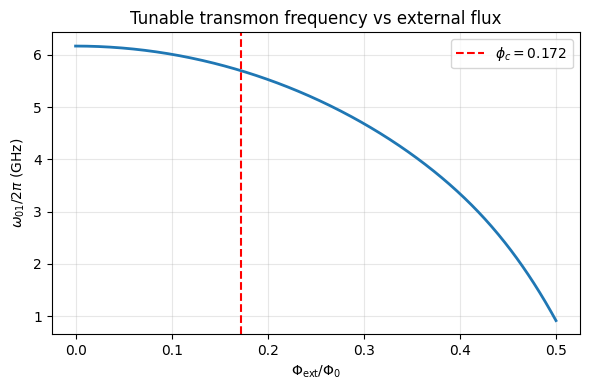

In [ ]:
phi_plot = np.linspace(0, 0.5, 501)
w1_plot  = np.array([float(w1_interp(p)) for p in phi_plot])
plt.figure(figsize=(6,4))
plt.plot(phi_plot, w1_plot, lw=2)
plt.axvline(flux_cphase, ls='--', color='red', label=f'$\\phi_c = {flux_cphase:.3f}$')
plt.xlabel(r'$\Phi_\mathrm{ext}/\Phi_0$')
plt.ylabel(r'$\omega_{01}/2\pi$ (GHz)')
plt.title('Tunable transmon frequency vs external flux')
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
#plt.savefig('fig_freq_vs_flux.pdf', dpi=150)

# Why the minimum $|11\rangle$–$|20\rangle$ gap is $\approx 2\sqrt{2}\,g$ :

We use the exchange coupling:
$$
H_{\mathrm{int}} = g\left(a_1^\dagger a_2 + a_1 a_2^\dagger\right).
$$

The term $a_1^\dagger a_2$ connects $|11\rangle \to |20\rangle$:
$$
a_2|1\rangle=\sqrt{1}\,|0\rangle,\qquad a_1^\dagger|1\rangle=\sqrt{2}\,|2\rangle
$$
so
$$
a_1^\dagger a_2|11\rangle=\sqrt{2}\,|20\rangle
\quad\Rightarrow\quad
\langle 20|H_{\mathrm{int}}|11\rangle = (\sqrt{2}g).
$$


Near resonance, approximate by a 2x2 block (Krantz eq. 116):
$$
H \approx
\begin{pmatrix}
E_{11} & \sqrt{2}\,g\\
\sqrt{2}\,g & E_{20}
\end{pmatrix}.
$$
At $E_{11}=E_{20}$, eigenvalues are $E\pm \sqrt{2}g$, so the gap is
$$
\Delta f_{\min} = 2\sqrt{2}\,g.
$$

For $g=10\,\mathrm{MHz}$:
$$
2\sqrt{2}g \approx 28.3\,\mathrm{MHz}
$$


 /usr/local/lib/python3.13/dist-packages/qutip/core/coefficient.py: 199

P11_final  = 0.990461
P20_final  = 8.479243e-03
P02_final  = 1.059394e-03
Leak_final = 9.538636e-03
T_total_ns = 44.00


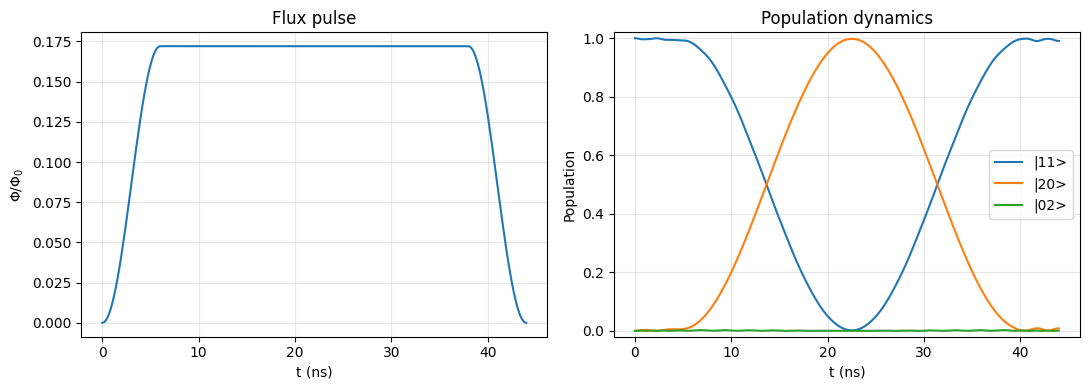

In [ ]:
#speed knobs
N_STEPS = 30000 #integrator max internal steps
N_T = 201  #time samples for single-run plots (lower is faster)
RTOL = 1e-5
ATOL = 1e-7


#1) flux pulse (smoothed square)
def flux_pulse(t, phi_idle, phi_hold, t_rise, t_hold):
    t = float(t)
    phi_idle = float(phi_idle); phi_hold = float(phi_hold)
    t_rise = float(t_rise); t_hold = float(t_hold)

    if t < 0:
        return phi_idle
    if t < t_rise:
        x = t / t_rise
        return phi_idle + (phi_hold - phi_idle) * np.sin(np.pi*x/2)**2
    if t < t_rise + t_hold:
        return phi_hold
    if t < 2*t_rise + t_hold:
        x = (t - (t_rise + t_hold)) / t_rise
        return phi_hold - (phi_hold - phi_idle) * np.sin(np.pi*x/2)**2
    return phi_idle


#2) time dependent hamiltonian coeffs
def c_w1(t, args):
    phi = float(flux_pulse(t, args["phi_idle"], args["phi_hold"], args["t_rise"], args["t_hold"]))
    return 2*np.pi * float(w1_interp(phi))

def c_a1half(t, args):
    phi = float(flux_pulse(t, args["phi_idle"], args["phi_hold"], args["t_rise"], args["t_hold"]))
    return 2*np.pi * 0.5 * float(a1_interp(phi))

H_t = [
    H2 + Hint,
    [n1, c_w1],
    [kerr1, c_a1half],
]


#3) basis kets
ket00 = qt.tensor(qt.basis(N,0), qt.basis(N,0))
ket01 = qt.tensor(qt.basis(N,0), qt.basis(N,1))
ket10 = qt.tensor(qt.basis(N,1), qt.basis(N,0))
ket11 = qt.tensor(qt.basis(N,1), qt.basis(N,1))

ket20 = qt.tensor(qt.basis(N,2), qt.basis(N,0))
ket02 = qt.tensor(qt.basis(N,0), qt.basis(N,2))

comp_kets = [ket00, ket01, ket10, ket11]


# 4)single gate run |11> for plots + print metrics
phi_idle = 0.0
phi_hold = float(flux_cphase) # start at cphase
t_rise = 6.0
t_hold = 32.0

args_base = {
    "phi_idle": float(phi_idle),
    "phi_hold": float(phi_hold),
    "t_rise": float(t_rise),
    "t_hold": float(t_hold),
}

T_total = 2*args_base["t_rise"] + args_base["t_hold"]
tlist = np.linspace(0, T_total, N_T)

opts = {"rtol": RTOL, "atol": ATOL, "nsteps": int(N_STEPS)}

res11 = qt.sesolve(H_t, ket11, tlist, args=args_base, options=opts)

# populations
P11 = np.array([np.abs(ket11.overlap(st))**2 for st in res11.states])
P20 = np.array([np.abs(ket20.overlap(st))**2 for st in res11.states])
P02 = np.array([np.abs(ket02.overlap(st))**2 for st in res11.states])

#correct leakage (outside comp subs)
def P_comp(st):
    return sum(np.abs(k.overlap(st))**2 for k in comp_kets)

Pcomp = np.array([P_comp(st) for st in res11.states])
Leak = 1.0 - Pcomp

#flux waveform for plotting
phi_wave = np.array([flux_pulse(t, args_base["phi_idle"], args_base["phi_hold"],
                                args_base["t_rise"], args_base["t_hold"]) for t in tlist])

print(f"P11_final  = {P11[-1]:.6f}")
print(f"P20_final  = {P20[-1]:.6e}")
print(f"P02_final  = {P02[-1]:.6e}")
print(f"Leak_final = {Leak[-1]:.6e}")
#print(f"Leak_max   = {Leak.max():.6f}")
print(f"T_total_ns = {T_total:.2f}")


# 5) plots: pulse and state evolution
fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].plot(tlist, phi_wave)
axs[0].set_title("Flux pulse")
axs[0].set_xlabel("t (ns)")
axs[0].set_ylabel(r"$\Phi/\Phi_0$")
axs[0].grid(alpha=0.3)

axs[1].plot(tlist, P11, label="|11>")
axs[1].plot(tlist, P20, label="|20>")
axs[1].plot(tlist, P02, label="|02>")
axs[1].set_title("Population dynamics")
axs[1].set_xlabel("t (ns)")
axs[1].set_ylabel("Population")
axs[1].set_ylim(-0.02, 1.02)
axs[1].grid(alpha=0.3)
axs[1].legend()

plt.tight_layout()
plt.show()



computing chevrons:


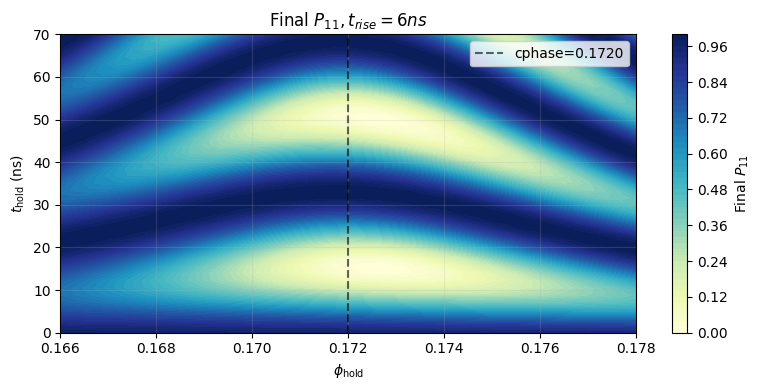

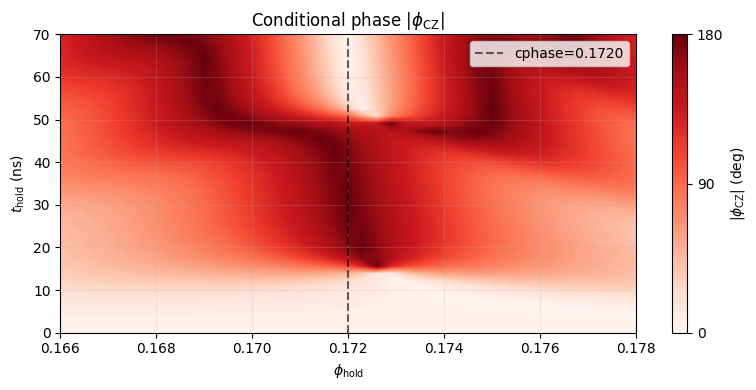

In [ ]:
#fast chevrons

#knobs
DT_MAP = 0.25 # ns (0.2–0.5 ns larger is faster)
MAP_NPHI = 41  # x-res
MAP_NTHOLD = 41 #y-res

# x-axis: centered at cphase, symmetric range
phi_span = 0.006  # a bit less to a bit more around cphase
phi_grid = flux_cphase + np.linspace(-phi_span, phi_span, MAP_NPHI)

#y-axis: t_hold from 0 to 70 ns
t_hold_grid = np.linspace(0.0, 70.0, MAP_NTHOLD)

# keeping existing t_rise from args_base
phi_idle = float(args_base["phi_idle"])
t_rise   = float(args_base["t_rise"])


#precompute constant numpy matrices (rad/ns)
Hconst_np = (H2 + Hint).full()
n1_np     = n1.full()
kerr1_np  = kerr1.full()


#computational kets (numpy column vectors)
ket00_np = ket00.full()
ket01_np = ket01.full()
ket10_np = ket10.full()
ket11_np = ket11.full()

#helpers for phases
def wrap_deg_signed(x):
    # wrap to (-180, 180)
    return (x + 180.0) % 360.0 - 180.0

def cz_deg_0_180(phi_deg_signed):
    #convert signed (-180,180) to (0,180)
    return abs(phi_deg_signed)


def propagate_P11_and_phase(phi_hold, t_hold):
    """
    to propagate 4 basis states at the same time through the same U(t)
    returns:
    P11_final
    phiCZ degrees
    """
    phi_hold = float(phi_hold)
    t_hold = float(t_hold)

    Ttot = 2*t_rise + t_hold
    nsteps = int(np.ceil(Ttot / DT_MAP))
    tlist = np.linspace(0.0, Ttot, nsteps + 1)
    dt = tlist[1] - tlist[0]

    #flux waveform
    phi_t = np.array([flux_pulse(t, phi_idle, phi_hold, t_rise, t_hold) for t in tlist])

    # w1(t), a1(t) in GHz -> rad/ns by 2π
    w1_t = 2*np.pi * np.array([float(w1_interp(p)) for p in phi_t])
    a1h_t = 2*np.pi * 0.5 * np.array([float(a1_interp(p)) for p in phi_t]) #(alpha1/2)

    #propagate 4 states together, columns are |00>,|01>,|10>,|11>
    Psi = np.hstack([ket00_np, ket01_np, ket10_np, ket11_np]) #(dim,4)

    for k in range(nsteps):
        #midpoint Hamiltonian
        w_mid = 0.5*(w1_t[k]  + w1_t[k+1])
        a_mid = 0.5*(a1h_t[k] + a1h_t[k+1])

        Hmid = Hconst_np + w_mid*n1_np + a_mid*kerr1_np
        U = la.expm(-1j * Hmid * dt)
        Psi = U @ Psi

    #final overlaps u_ij = <ij|psi_ij>
    u00 = (ket00_np.conj().T @ Psi[:, [0]])[0,0]
    u01 = (ket01_np.conj().T @ Psi[:, [1]])[0,0]
    u10 = (ket10_np.conj().T @ Psi[:, [2]])[0,0]
    u11 = (ket11_np.conj().T @ Psi[:, [3]])[0,0]

    #final P11 return for starting in |11>
    P11_final = float(abs(u11)**2)

    # CZ phase in degrees
    phiCZ_deg_signed = wrap_deg_signed(np.degrees(np.angle(u11*u00*np.conj(u10*u01))))

    phiCZ_deg = cz_deg_0_180(phiCZ_deg_signed)

    return P11_final, phiCZ_deg


# allocate maps
P11_final_map = np.zeros((len(t_hold_grid), len(phi_grid)))
phiCZ_map_deg = np.zeros_like(P11_final_map)

print("\ncomputing chevrons:")
for iy, th in enumerate(t_hold_grid):
    for ix, ph in enumerate(phi_grid):
        P11f, czdeg = propagate_P11_and_phase(ph, th)
        P11_final_map[iy, ix] = P11f
        phiCZ_map_deg[iy, ix] = czdeg
    #if (iy % max(1, len(t_hold_grid)//5) == 0):
        #print(f"  row {iy+1}/{len(t_hold_grid)} done")


X, Y = np.meshgrid(phi_grid, t_hold_grid)




#final P11
plt.figure(figsize=(8,4))
cp = plt.contourf(X, Y, P11_final_map, 60, cmap="YlGnBu", vmin=0, vmax=1, antialiased=False)
plt.colorbar(cp, label="Final $P_{11}$")
plt.axvline(flux_cphase, color="k", ls="--", alpha=0.6, label=f"cphase={flux_cphase:.4f}")
plt.title("Final $P_{11}, t_{rise} = 6ns$")
plt.xlabel(r"$\phi_{\rm hold}$")
plt.ylabel(r"$t_{\rm hold}$ (ns)")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

#phase
plt.figure(figsize=(8,4))
cp = plt.contourf(X, Y, phiCZ_map_deg, 80, cmap="Reds", vmin=0, vmax=180)
cbar = plt.colorbar(cp, label=r"$|\phi_{\rm CZ}|$ (deg)")
cbar.set_ticks([0, 90, 180])
plt.axvline(flux_cphase, color="k", ls="--", alpha=0.6, label=f"cphase={flux_cphase:.4f}")
plt.title(r"Conditional phase $|\phi_{\rm CZ}|$")
plt.xlabel(r"$\phi_{\rm hold}$")
plt.ylabel(r"$t_{\rm hold}$ (ns)")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
#we pick the earliest t_hold that meets thresholds in the first lobe (wave)
#then maximize P11 within that earliest row

PHERR_CHEV_MAX = 8.0 #deg
P11_MIN_CHEV   = 0.99

phase_err_map = np.abs(180.0 - phiCZ_map_deg)

#restrict auto-pick to be near cphase (prevents jumping far in phi)
PHI_PICK_MAX = 0.001 # choose within +- 0.001 of cphase
phi_near = (np.abs(phi_grid - flux_cphase) <= PHI_PICK_MAX)

ok = (phase_err_map <= PHERR_CHEV_MAX) & (P11_final_map >= P11_MIN_CHEV) & phi_near[np.newaxis, :]

if np.any(ok):
    #earliest t_hold row that has any acceptable point
    iy_candidates = np.where(np.any(ok, axis=1))[0]
    iy0_first = int(iy_candidates[0])

    #we look within the first few acceptable rows (first lobe window)
    N_EARLY_ROWS = 4  # 4 rows ~ small extra time range
    iy_window = iy_candidates[iy_candidates <= iy0_first + N_EARLY_ROWS]

    #best point in early window: max P11, tie break min phase err, tie break min time
    best = None
    for iy in iy_window:
        row_ok = ok[iy, :]
        if not np.any(row_ok):
            continue
        ix_list = np.where(row_ok)[0]
        for ix in ix_list:
            P = float(P11_final_map[iy, ix])
            pe = float(phase_err_map[iy, ix])
            th = float(t_hold_grid[iy])
            cand = (-P, pe, th, iy, ix) #maximize P -> minimize -P
            if (best is None) or (cand < best):
                best = cand

    _, _, _, iy0, ix0 = best

else:
    #fallback: pick smallest phase error, then best P11 within that
    iy0, ix0 = np.unravel_index(np.argmin(phase_err_map), phase_err_map.shape)
    print("nothing near cphase")
#if phase error is huge, warn
if abs(180.0 - float(phiCZ_map_deg[iy0, ix0])) > 20.0:
    print("auto-pick is far from CZ")


th0_auto = float(t_hold_grid[iy0])
ph0_auto = float(phi_grid[ix0])
cz0_auto = float(phiCZ_map_deg[iy0, ix0])
p110_auto = float(P11_final_map[iy0, ix0])

print("\nauto chevron pick:")
print(f"  phi_hold = {ph0_auto:.6f}")
print(f"  t_hold   = {th0_auto:.3f} ns")
print(f"  P11      = {p110_auto:.6f}")
print(f"  |phiCZ|  = {cz0_auto:.3f} deg (err {abs(180-cz0_auto):.3f} deg)")




auto chevron pick:
  phi_hold = 0.172000
  t_hold   = 33.250 ns
  P11      = 0.999729
  |phiCZ|  = 178.317 deg (err 1.683 deg)


In [ ]:
#sweep helper: propagate + return (P11_final, leak_final, phiCZ)

def propagate_P11_leak_phase(phi_hold, t_hold, t_rise, DT_MAP=0.5):
    """
    time-ordered propagation for 4 input states
    returns:
    P11_final = |<11|psi_11(T)>|^2
    leak_final = 1 - sum_{comp} |<comp|psi_11(T)>|^2
    phiCZ_deg_0_180 = abs(wrapped CZ phase) in degrees

    this requires pre existing globals:
    flux_pulse, phi_idle,
    w1_interp, a1_interp,
    Hconst_np, n1_np, kerr1_np,
    ket00_np, ket01_np, ket10_np, ket11_np,
    wrap_deg_signed
    """
    phi_hold = float(phi_hold)
    t_hold = float(t_hold)
    t_rise = float(t_rise)

    Ttot = 2*t_rise + t_hold
    nsteps = int(np.ceil(Ttot / float(DT_MAP)))
    tlist_local = np.linspace(0.0, Ttot, nsteps + 1)
    dt = tlist_local[1] - tlist_local[0]

    #flux waveform
    phi_t = np.array([flux_pulse(t, phi_idle, phi_hold, t_rise, t_hold) for t in tlist_local])

    #w1(t), alpha1(t) in GHz -> rad/ns by 2π
    w1_t  = 2*np.pi * np.array([float(w1_interp(p)) for p in phi_t])
    a1h_t = 2*np.pi * 0.5 * np.array([float(a1_interp(p)) for p in phi_t]) # alpha1/2

    #propagate 4 states together, columns are |00>,|01>,|10>,|11>
    Psi = np.hstack([ket00_np, ket01_np, ket10_np, ket11_np])  #(dim,4)

    for k in range(nsteps):
        w_mid = 0.5*(w1_t[k]  + w1_t[k+1])
        a_mid = 0.5*(a1h_t[k] + a1h_t[k+1])

        Hmid = Hconst_np + w_mid*n1_np + a_mid*kerr1_np
        U = la.expm(-1j * Hmid * dt)
        Psi = U @ Psi

    #diagonal overlaps u_ij = <ij|psi_ij>
    u00 = (ket00_np.conj().T @ Psi[:, [0]])[0,0]
    u01 = (ket01_np.conj().T @ Psi[:, [1]])[0,0]
    u10 = (ket10_np.conj().T @ Psi[:, [2]])[0,0]
    u11 = (ket11_np.conj().T @ Psi[:, [3]])[0,0]

    P11_final = float(abs(u11)**2)

    #leak at final time for run starting in |11>
    v11 = Psi[:, [3]]
    c00 = (ket00_np.conj().T @ v11)[0,0]
    c01 = (ket01_np.conj().T @ v11)[0,0]
    c10 = (ket10_np.conj().T @ v11)[0,0]
    c11 = (ket11_np.conj().T @ v11)[0,0]
    P_comp_final = float(abs(c00)**2 + abs(c01)**2 + abs(c10)**2 + abs(c11)**2)
    leak_final = float(1.0 - P_comp_final)

    #robust CZ phase in degrees
    phiCZ_deg_signed = wrap_deg_signed(np.degrees(np.angle(u11*u00*np.conj(u10*u01))))
    phiCZ_deg_0_180 = abs(float(phiCZ_deg_signed))

    return P11_final, leak_final, phiCZ_deg_0_180


In [ ]:
#sweep with thresholds and candidates printout

#sweep ranges
phi_grid_fast = np.linspace(ph0_auto - 0.0015, ph0_auto + 0.0015, 21)
t_hold_grid_fast = np.linspace(th0_auto - 6.0, th0_auto + 6.0, 25)
t_rise_grid_fast = np.array([2, 4, 6, 8, 10, 12], dtype=float)

#thresholds
P11_MIN   = 0.990
LEAK_MAX  = 0.005 # 0.5% (outside comp. subs.)
PHERR_MAX = 5.0 # degrees, error from 180

# scoring among the survivors
W_PHERR = 1.0
W_P11   = 2.0
W_LEAK  = 50.0
W_TIME  = 0.02

survivors = []
best_any = None

print("\nsweeping with thresholds:")

for tr in t_rise_grid_fast:
    for th in t_hold_grid_fast:
        Ttot = 2*float(tr) + float(th)
        for ph in phi_grid_fast:
            P11f, leakf, czdeg = propagate_P11_leak_phase(ph, th, tr)

            pherr = abs(180.0 - float(czdeg))
            score = (
                W_PHERR * pherr
                + W_P11  * (1.0 - float(P11f))
                + W_LEAK * float(leakf)
                + W_TIME * Ttot
            )

            #best overall (even if it fails thresholds)
            if (best_any is None) or (score < best_any[0]):
                best_any = (score, float(tr), float(ph), float(th), float(P11f), float(leakf), float(czdeg), float(Ttot), float(pherr))

            # threshold filter
            if (P11f >= P11_MIN) and (leakf <= LEAK_MAX) and (pherr <= PHERR_MAX):
                survivors.append((score, float(tr), float(ph), float(th), float(P11f), float(leakf), float(czdeg), float(Ttot), float(pherr)))

    print(f"t_rise={tr:.1f} ns")

#sort survivors by score (lowest is best)
survivors.sort(key=lambda x: x[0])

s, tr, ph, th, P11f, leakf, cz, Ttot, pherr = best_any

print(f"\nThresholds: P11>={P11_MIN}, leak<={LEAK_MAX}, phase_err<={PHERR_MAX} deg")
print(f"{len(survivors)} candidates:\n")

TOPK = min(12, len(survivors))
for k in range(TOPK):
    s, tr, ph, th, P11f, leakf, cz, Ttot, pherr = survivors[k]
    print(f"[{k+1:02d}] Ttot={Ttot:7.3f} ns, t_rise={tr:5.1f} ns, t_hold={th:6.2f} ns | phi={ph:.6f} | "
          f"P11={P11f:.6f}, leak={leakf:.4e}, |phiCZ|={cz:7.3f} (error (degrees) {pherr:5.2f})")



sweeping with thresholds:
t_rise=2.0 ns
t_rise=4.0 ns
t_rise=6.0 ns
t_rise=8.0 ns
t_rise=10.0 ns
t_rise=12.0 ns

Thresholds: P11>=0.99, leak<=0.005, phase_err<=5.0 deg
36 candidates:

[01] Ttot= 40.250 ns, t_rise=  4.0 ns, t_hold= 32.25 ns | phi=0.172000 | P11=0.998967, leak=1.0330e-03, |phiCZ|=179.660 (error (degrees)  0.34)
[02] Ttot= 38.250 ns, t_rise=  2.0 ns, t_hold= 34.25 ns | phi=0.172000 | P11=0.998817, leak=1.1826e-03, |phiCZ|=179.488 (error (degrees)  0.51)
[03] Ttot= 40.750 ns, t_rise=  4.0 ns, t_hold= 32.75 ns | phi=0.172000 | P11=0.999762, leak=2.3835e-04, |phiCZ|=179.445 (error (degrees)  0.55)
[04] Ttot= 46.750 ns, t_rise=  8.0 ns, t_hold= 30.75 ns | phi=0.172000 | P11=0.997241, leak=2.7588e-03, |phiCZ|=179.591 (error (degrees)  0.41)
[05] Ttot= 38.750 ns, t_rise=  2.0 ns, t_hold= 34.75 ns | phi=0.172000 | P11=0.999383, leak=6.1655e-04, |phiCZ|=179.175 (error (degrees)  0.82)
[06] Ttot= 41.250 ns, t_rise=  4.0 ns, t_hold= 33.25 ns | phi=0.172000 | P11=0.996200, leak=3.7

In [ ]:
#choose seed for refinement from sweep results
if len(survivors) > 0:
    #survivors entry = score, tr, ph, th, P11f, leakf, czdeg, Ttot, pherr
    #choose best survivor automatically
    s0, tr_seed, ph_seed, th_seed, P11_seed, leak_seed, cz_seed, Ttot_seed, pherr_seed = survivors[0]

    print("\nchosen seed for refinement:")
    print(f"  t_rise = {tr_seed:.3f} ns")
    print(f"  phi_hold = {ph_seed:.6f}")
    print(f"  t_hold = {th_seed:.3f} ns")
    print(f"  P11 = {P11_seed:.6f}, leak = {leak_seed:.3e}, |phiCZ| = {cz_seed:.3f} deg")
else:
    #fallback if no threshold passing candidates
    s0, tr_seed, ph_seed, th_seed, P11_seed, leak_seed, cz_seed, Ttot_seed, pherr_seed = best_any

    print("\nno threshold passing survivors. using best_any as refinement")
    print(f"  t_rise = {tr_seed:.3f} ns")
    print(f"  phi_hold = {ph_seed:.6f}")
    print(f"  t_hold = {th_seed:.3f} ns")
    print(f"  P11 = {P11_seed:.6f}, leak = {leak_seed:.3e}, |phiCZ| = {cz_seed:.3f} deg")


chosen seed for refinement:
  t_rise = 4.000 ns
  phi_hold = 0.172000
  t_hold = 32.250 ns
  P11 = 0.998967, leak = 1.033e-03, |phiCZ| = 179.660 deg


In [ ]:
#refinement around chosen candidate: more accurate DT_MAP

# use auto seeds from sweep cell
tr0 = float(tr_seed)
th0 = float(th_seed)
ph0 = float(ph_seed)

#to use chevron auto pick instead:
# th0 = float(th0_auto)
# ph0 = float(ph0_auto)


DT_REFINE = 0.25 #more accurate than 0.5

#small local windows
phi_ref = np.linspace(ph0 - 0.00025, ph0 + 0.00025, 51)
t_hold_ref = np.linspace(th0 - 2.0, th0 + 2.0, 41)
t_rise_ref = np.array([tr0]) #hmm keep fixed first, maybe I can add neighbors later

best = None
print("\nrefining around candidate:")

for tr in t_rise_ref:
    for th in t_hold_ref:
        Ttot = 2*float(tr) + float(th)
        for ph in phi_ref:
            P11f, leakf, czdeg = propagate_P11_leak_phase(ph, th, tr, DT_MAP=DT_REFINE)
            pherr = abs(180.0 - float(czdeg))

            #score: prioritize leakage + P11, then phase, then time
            score = 200.0*leakf + 10.0*(1.0-P11f) + 1.0*pherr + 0.01*Ttot

            if (best is None) or (score < best[0]):
                best = (score, float(tr), float(ph), float(th), float(P11f), float(leakf), float(czdeg), float(Ttot), float(pherr))

score_b, tr_b, ph_b, th_b, P11_b, leak_b, cz_b, Ttot_b, pherr_b = best

print("\nrefined best:")
print(f"t_rise={tr_b:.3f} ns, t_hold={th_b:.3f} ns, Ttot={Ttot_b:.3f} ns, phi_hold={ph_b:.6f}")
print(f"P11={P11_b:.6f}, leak={leak_b:.6e}, |phiCZ|={cz_b:.3f} deg, ph_err={pherr_b:.3f} deg")



refining around candidate:

refined best:
t_rise=4.000 ns, t_hold=32.450 ns, Ttot=40.450 ns, phi_hold=0.171990
P11=0.999890, leak=1.095262e-04, |phiCZ|=179.887 deg, ph_err=0.113 deg


In [ ]:
#apply refined best parameters

args_base["t_rise"]   = float(tr_b)
args_base["t_hold"]   = float(th_b)
args_base["phi_hold"] = float(ph_b)

T_total = 2*args_base["t_rise"] + args_base["t_hold"]
tlist = np.linspace(0, T_total, N_T)

print("refined best:")
print("t_rise =", args_base["t_rise"])
print("t_hold =", args_base["t_hold"])
print("T_total =", T_total)
print("phi_hold =", args_base["phi_hold"])


refined best:
t_rise = 4.0
t_hold = 32.45
T_total = 40.45
phi_hold = 0.17199


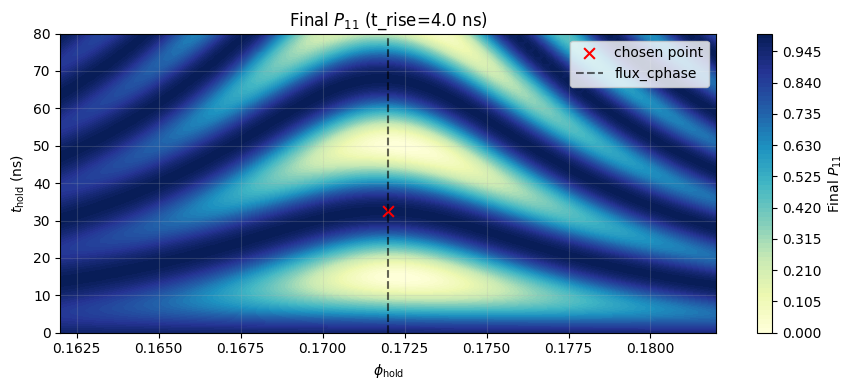

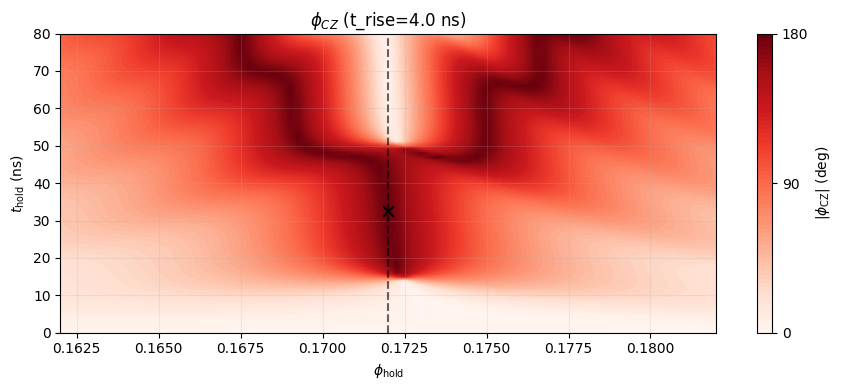

In [ ]:
#new chevrons

DT_MAP = 0.5

#windows
phi_grid = np.linspace(flux_cphase - 0.010, flux_cphase + 0.010, 81)
t_hold_grid = np.linspace(0.0, 80.0, 81)

tr_plot = float(args_base["t_rise"]) #use the final chosen rise time
ph_star = float(args_base["phi_hold"]) #final chosen point
th_star = float(args_base["t_hold"])

P11_map = np.zeros((len(t_hold_grid), len(phi_grid)))
CZ_map  = np.zeros_like(P11_map)

for iy, th in enumerate(t_hold_grid):
    for ix, ph in enumerate(phi_grid):
        P11f, leakf, czdeg = propagate_P11_leak_phase(ph, th, tr_plot, DT_MAP=DT_MAP)
        P11_map[iy, ix] = P11f
        CZ_map[iy, ix] = czdeg

X, Y = np.meshgrid(phi_grid, t_hold_grid)

plt.figure(figsize=(9,4))
cp = plt.contourf(X, Y, P11_map, 80, cmap="YlGnBu", vmin=0, vmax=1)
plt.colorbar(cp, label="Final $P_{11}$")
plt.scatter([ph_star], [th_star], s=60, c="r", marker="x", label="chosen point")
plt.axvline(flux_cphase, color="k", ls="--", alpha=0.6, label="flux_cphase")
plt.title(f"Final $P_{{11}}$ (t_rise={tr_plot:.1f} ns)")
plt.xlabel(r"$\phi_{\rm hold}$")
plt.ylabel(r"$t_{\rm hold}$ (ns)")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,4))
cp = plt.contourf(X, Y, CZ_map, 80, cmap="Reds", vmin=0, vmax=180)
cbar = plt.colorbar(cp, label=r"$|\phi_{\rm CZ}|$ (deg)")
cbar.set_ticks([0, 90, 180])
plt.scatter([ph_star], [th_star], s=60, c="k", marker="x")
plt.axvline(flux_cphase, color="k", ls="--", alpha=0.6)
plt.title(f"$\\phi_{{CZ}}$ (t_rise={tr_plot:.1f} ns)")
plt.xlabel(r"$\phi_{\rm hold}$")
plt.ylabel(r"$t_{\rm hold}$ (ns)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [ ]:
#qutip local sweep in 1D: optimize t_hold around current args_base
#goal is maximize P11_return while keeping phiCZ near 180 deg

opts_sweep = {"rtol": 1e-8, "atol": 1e-10, "nsteps": 120000, "max_step": 0.05}

def wrap_deg_signed(x):
    return (x + 180.0) % 360.0 - 180.0

def cz_abs_from_final_states(res00, res01, res10, res11):
    u00T = ket00.overlap(res00.states[-1])
    u01T = ket01.overlap(res01.states[-1])
    u10T = ket10.overlap(res10.states[-1])
    u11T = ket11.overlap(res11.states[-1])
    czT = (u11T*u00T) * np.conj(u10T*u01T)
    phi_signed = wrap_deg_signed(np.degrees(np.angle(czT)))
    return abs(float(phi_signed))

#center point (current args_base)
tr0 = float(args_base["t_rise"])
ph0 = float(args_base["phi_hold"])
th0 = float(args_base["t_hold"])

#sweep window
t_hold_list = np.linspace(th0 - 0.30, th0 + 0.30, 61) # +-0.30 ns, step 0.01 ns

#constraints
PHERR_MAX = 0.5 #deg from 180

best = None
cands = []

print("\nqutip local sweep:")
print("t_rise =", tr0, ", phi_hold =", ph0, ", t_hold_center =", th0)

for th in t_hold_list:
    args_tmp = dict(args_base)
    args_tmp["t_hold"] = float(th)

    T_total = 2*args_tmp["t_rise"] + args_tmp["t_hold"]
    tlist_tmp = np.linspace(0, T_total, N_T)

    res00 = qt.sesolve(H_t, ket00, tlist_tmp, args=args_tmp, options=opts_sweep)
    res01 = qt.sesolve(H_t, ket01, tlist_tmp, args=args_tmp, options=opts_sweep)
    res10 = qt.sesolve(H_t, ket10, tlist_tmp, args=args_tmp, options=opts_sweep)
    res11 = qt.sesolve(H_t, ket11, tlist_tmp, args=args_tmp, options=opts_sweep)

    #return for |11> input
    u11T = ket11.overlap(res11.states[-1])
    P11 = float(abs(u11T)**2)

    #leakage for |11> input (comp subspace)
    c00 = ket00.overlap(res11.states[-1])
    c01 = ket01.overlap(res11.states[-1])
    c10 = ket10.overlap(res11.states[-1])
    c11 = ket11.overlap(res11.states[-1])
    Pcomp = float(abs(c00)**2 + abs(c01)**2 + abs(c10)**2 + abs(c11)**2)
    leak = float(1.0 - Pcomp)

    #CZ
    cz_abs = float(cz_abs_from_final_states(res00, res01, res10, res11))
    pherr = abs(180.0 - cz_abs)

    cands.append((float(th), P11, leak, cz_abs, pherr))

    #keep best under phase constraint
    if pherr <= PHERR_MAX:
        #score: prioritize P11, then leakage
        score = -(P11) + 50.0*leak
        if (best is None) or (score < best[0]):
            best = (score, float(th), P11, leak, cz_abs, pherr)

#print summary
cands = np.array(cands, dtype=float)

print("\nbest candidate:")
if best is None:
    print("no point satisfied phase constraint")
else:
    score, th_best_q, P11_best_q, leak_best_q, cz_best_q, pherr_best_q = best
    print(f"t_hold_best = {th_best_q:.2f} ns")
    Ttot_best_q = 2*tr0 + th_best_q
    print(f"T_total     = {Ttot_best_q:.2f} ns")
    print(f"P11_final   = {P11_best_q:.6f}")
    print(f"Leak_final  = {leak_best_q:.6f}")
    print(f"phiCZ       = {cz_best_q:.6f} deg (err {pherr_best_q:.3f} deg)")


    #apply it so later cells use it automatically
    args_base["t_hold"] = float(th_best_q)
    T_total = 2*args_base["t_rise"] + args_base["t_hold"]
    tlist = np.linspace(0, T_total, N_T)

    print("\nnew t_hold and t_total are applied to args_base, and rebuilt tlist")



qutip local sweep:
t_rise = 4.0 , phi_hold = 0.17199 , t_hold_center = 32.45

best candidate:
t_hold_best = 32.51 ns
T_total     = 40.51 ns
P11_final   = 0.999925
Leak_final  = 0.000075
phiCZ       = 179.849205 deg (err 0.151 deg)

new t_hold and t_total are applied to args_base, and rebuilt tlist


Final parameters:
P11_final  = 0.999925
P20_final  = 8.839433e-06
P02_final  = 6.587526e-05
Leak_final = 7.471470e-05


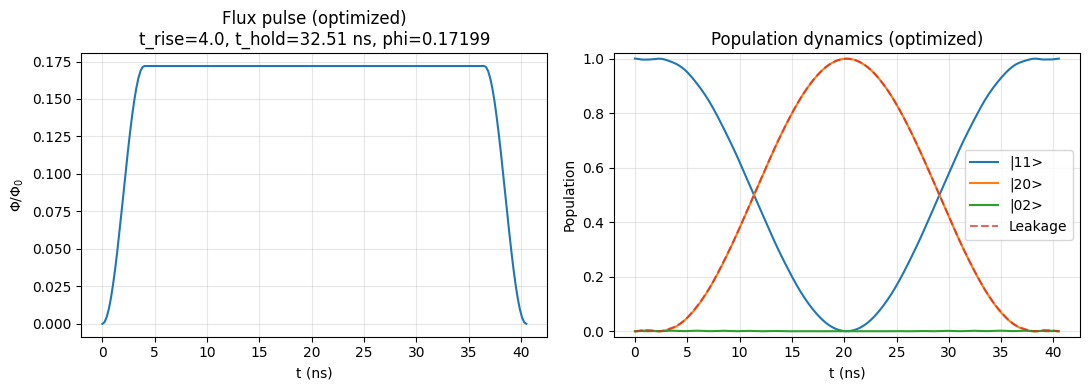

In [ ]:
#flux pulse + population dynamics with final best parameters
print("Final parameters:")
phi_wave_opt = np.array([flux_pulse(t, args_base["phi_idle"], args_base["phi_hold"],
                                     args_base["t_rise"], args_base["t_hold"])
                          for t in tlist])

res11_opt = qt.sesolve(H_t, ket11, tlist, args=args_base,
                        options={"rtol": 1e-8, "atol": 1e-10, "nsteps": 120000, "max_step": 0.05})

P11_opt_t = np.array([np.abs(ket11.overlap(st))**2 for st in res11_opt.states])
P20_opt_t = np.array([np.abs(ket20.overlap(st))**2 for st in res11_opt.states])
P02_opt_t = np.array([np.abs(ket02.overlap(st))**2 for st in res11_opt.states])
Leak_opt_t = 1.0 - np.array([sum(np.abs(k.overlap(st))**2 for k in comp_kets)
                               for st in res11_opt.states])

print(f"P11_final  = {P11_opt_t[-1]:.6f}")
print(f"P20_final  = {P20_opt_t[-1]:.6e}")
print(f"P02_final  = {P02_opt_t[-1]:.6e}")
print(f"Leak_final = {Leak_opt_t[-1]:.6e}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].plot(tlist, phi_wave_opt)
axs[0].set_title(f"Flux pulse (optimized)\n"
                 f"t_rise={args_base['t_rise']:.1f}, t_hold={args_base['t_hold']:.2f} ns, "
                 f"phi={args_base['phi_hold']:.5f}")
axs[0].set_xlabel("t (ns)")
axs[0].set_ylabel(r"$\Phi/\Phi_0$")
axs[0].grid(alpha=0.3)

axs[1].plot(tlist, P11_opt_t, label="|11>")
axs[1].plot(tlist, P20_opt_t, label="|20>")
axs[1].plot(tlist, P02_opt_t, label="|02>")
axs[1].plot(tlist, Leak_opt_t, "--", label="Leakage", alpha=0.7)
axs[1].set_title("Population dynamics (optimized)")
axs[1].set_xlabel("t (ns)")
axs[1].set_ylabel("Population")
axs[1].set_ylim(-0.02, 1.02)
axs[1].grid(alpha=0.3)
axs[1].legend()

plt.tight_layout()
plt.show()

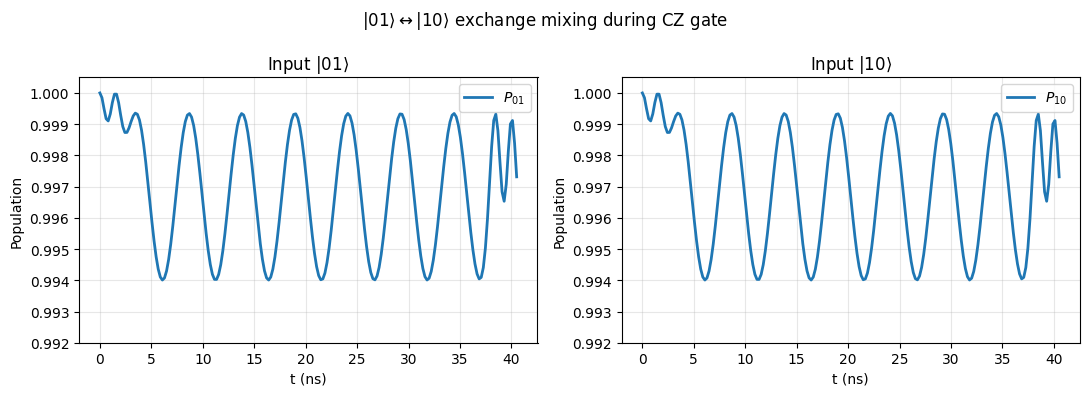

Final |01>→|10> transfer:  0.2687%
Final |10>→|01> transfer:  0.2687%
Peak |01>→|10> during gate: 0.5992%
Peak |10>→|01> during gate: 0.5992%

|01>-|10> detuning at gate point: Δ = 193.3 MHz
Coupling: g = 10.0 MHz
Rabi frequency at gate point: f = √(Δ²+4g²)/2 = 97.1 MHz
Rabi period: T = 10.3 ns
Expected oscillation amplitude: (g/Δ)² = (10/193)² = 0.2677%


In [ ]:
#exchange oscillations: |01> and |10> inputs through the final gate
#about |01><->|10> mixing visibility

opts_exch = {"rtol": 1e-8, "atol": 1e-10, "nsteps": 120000, "max_step": 0.05}

res01_opt = qt.sesolve(H_t, ket01, tlist, args=args_base, options=opts_exch)
res10_opt = qt.sesolve(H_t, ket10, tlist, args=args_base, options=opts_exch)

# populations for |01> input
P01_in01 = np.array([abs(ket01.overlap(s))**2 for s in res01_opt.states])
P10_in01 = np.array([abs(ket10.overlap(s))**2 for s in res01_opt.states])

#for |10> input
P10_in10 = np.array([abs(ket10.overlap(s))**2 for s in res10_opt.states])
P01_in10 = np.array([abs(ket01.overlap(s))**2 for s in res10_opt.states])



fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].plot(tlist, P01_in01, lw=2, label=r"$P_{01}$")
#axs[0].plot(tlist, P10_in01, lw=2, color="red",
#            label=r"$P_{10}$ (should be 0)")
axs[0].set_ylim(1.0 - 8e-3, 1.0 + 0.5e-3)
axs[0].set_xlabel("t (ns)")
axs[0].set_ylabel("Population")
axs[0].set_title(r"Input $|01\rangle$")
axs[0].legend()
axs[0].grid(alpha=0.3)

axs[1].plot(tlist, P10_in10, lw=2, label=r"$P_{10}$")
#axs[1].plot(tlist, P01_in10, lw=2, color="red",
#            label=r"$P_{01}$ (should be 0)")
axs[1].set_ylim(1.0 - 8e-3, 1.0 + 0.5e-3)
axs[1].set_xlabel("t (ns)")
axs[1].set_ylabel("Population")
axs[1].set_title(r"Input $|10\rangle$")
axs[1].legend()
axs[1].grid(alpha=0.3)

plt.suptitle(r"$|01\rangle \leftrightarrow |10\rangle$ exchange mixing during CZ gate")
plt.tight_layout()
plt.show()


#quantify
transfer_01_to_10 = float(P10_in01[-1])
transfer_10_to_01 = float(P01_in10[-1])
max_osc_01 = float(P10_in01.max())
max_osc_10 = float(P01_in10.max())

print(f"Final |01>→|10> transfer:  {transfer_01_to_10*100:.4f}%")
print(f"Final |10>→|01> transfer:  {transfer_10_to_01*100:.4f}%")
print(f"Peak |01>→|10> during gate: {max_osc_01*100:.4f}%")
print(f"Peak |10>→|01> during gate: {max_osc_10*100:.4f}%")


#Rabi frequency estimate at gate point
phi_hold_now = float(args_base["phi_hold"])
w1_gate = float(w1_interp(phi_hold_now))
delta_MHz = (w1_gate - w2) * 1000.0  # MHz
g_MHz = 0.01 * 1000.0  #10 MHz
f_rabi_MHz = np.sqrt(delta_MHz**2 + 4*g_MHz**2) / 2.0
period_ns   = 1000.0 / f_rabi_MHz

print(f"\n|01>-|10> detuning at gate point: Δ = {delta_MHz:.1f} MHz")
print(f"Coupling: g = {g_MHz:.1f} MHz")
print(f"Rabi frequency at gate point: f = √(Δ²+4g²)/2 = {f_rabi_MHz:.1f} MHz")
print(f"Rabi period: T = {period_ns:.1f} ns")
print(f"Expected oscillation amplitude: (g/Δ)² = ({g_MHz:.0f}/{delta_MHz:.0f})² = "
      f"{(g_MHz/delta_MHz)**2*100:.4f}%")

In [ ]:
#average gate fidelity from these four runs

res00_opt = qt.sesolve(H_t, ket00, tlist, args=args_base, options=opts_exch)

# build U_CZ from the four terminal states
basis_kets = [ket00, ket01, ket10, ket11]
res_list_opt = [res00_opt, res01_opt, res10_opt, res11_opt]

U_CZ_local = np.zeros((4, 4), dtype=complex)
for j, res in enumerate(res_list_opt):
    psiT = res.states[-1]
    for i, bk in enumerate(basis_kets):
        U_CZ_local[i, j] = bk.overlap(psiT)

#canonicalize: remove single-qubit Z phases
def closest_unitary_local(M):
    Ul, s, Vh = np.linalg.svd(M)
    return Ul @ Vh

U_unit = closest_unitary_local(U_CZ_local)
d_diag = np.diag(U_unit)
th = np.angle(d_diag)
a  = th[2] - th[0];  b = th[1] - th[0]
L  = np.diag(np.exp(-1j * np.array([0.0, b, a, a+b])))
U_can_local = L @ U_unit * np.exp(-1j * np.angle((L @ U_unit)[0, 0]))

U_CZ_ideal = np.diag([1.0, 1.0, 1.0, -1.0]).astype(complex)

def avg_gate_fidelity_local(U_actual, U_ideal):
    d = U_ideal.shape[0]
    return (abs(np.trace(U_ideal.conj().T @ U_actual))**2 + d) / (d * (d + 1))

F_CZ_here = avg_gate_fidelity_local(U_can_local, U_CZ_ideal)

print(f"Average gate fidelity:")
print(f"F_avg(CZ, after virtual-Z) = {F_CZ_here:.6f}")
print(f"Infidelity = {(1 - F_CZ_here)*100:.4f}%")


Average gate fidelity:
F_avg(CZ, after virtual-Z) = 0.998924
Infidelity = 0.1076%


In [ ]:
#how far from resonance is the current phi_hold?
phi_hold_now = float(args_base["phi_hold"])

w1_h = float(w1_interp(phi_hold_now))
a1_h = float(a1_interp(phi_hold_now))

E11_bare_GHz = w1_h + w2
E20_bare_GHz = 2.0*w1_h + a1_h
Delta_20_11_MHz = abs(E20_bare_GHz - E11_bare_GHz) * 1000.0

print(f"phi_hold = {phi_hold_now:.5f}")
print(f"frequency difference from the resonance is {Delta_20_11_MHz:.3f} MHz")

phi_hold = 0.17199
frequency difference from the resonance is 0.498 MHz


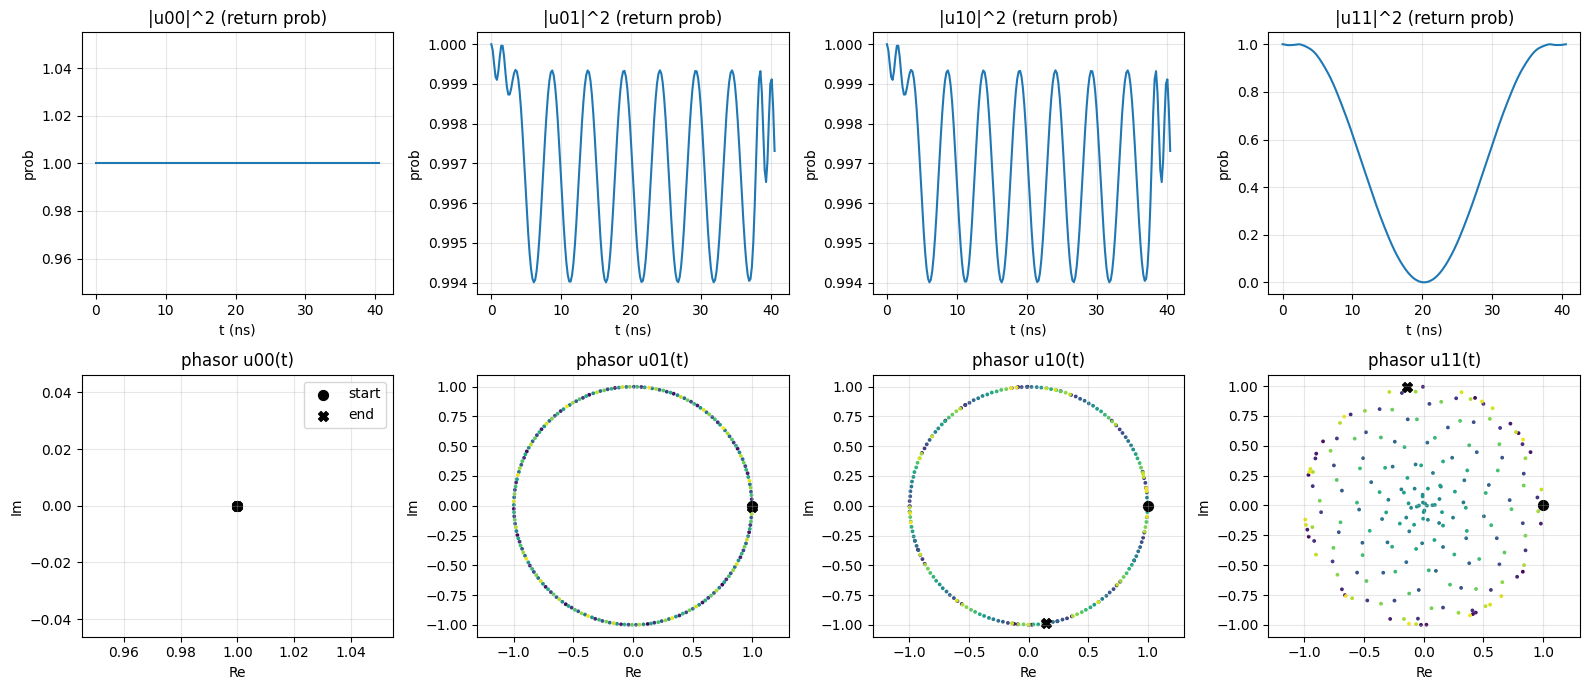


final return probs:
P00_final = 1.0
P01_final = 0.9973133583699818
P10_final = 0.9973133544179708
P11_final = 0.9999252856657155


In [ ]:
#evolve 00, 01, 10, 11
opts = {"rtol": 1e-10, "atol": 1e-12, "nsteps": 300000, "max_step": 0.02}

res00 = qt.sesolve(H_t, ket00, tlist, args=args_base, options=opts)
res01 = qt.sesolve(H_t, ket01, tlist, args=args_base, options=opts)
res10 = qt.sesolve(H_t, ket10, tlist, args=args_base, options=opts)
res11 = qt.sesolve(H_t, ket11, tlist, args=args_base, options=opts)

#return amplitudes u_ij(t) = <ij|psi_ij(t)>
u00 = np.array([ket00.overlap(st) for st in res00.states])
u01 = np.array([ket01.overlap(st) for st in res01.states])
u10 = np.array([ket10.overlap(st) for st in res10.states])
u11 = np.array([ket11.overlap(st) for st in res11.states])

P00_ret = np.abs(u00)**2
P01_ret = np.abs(u01)**2
P10_ret = np.abs(u10)**2
P11_ret = np.abs(u11)**2


#plot probabilities + phasors
fig, axs = plt.subplots(2, 4, figsize=(16, 7))

#probabilities
axs[0,0].plot(tlist, P00_ret); axs[0,0].set_title("|u00|^2 (return prob)")
axs[0,1].plot(tlist, P01_ret); axs[0,1].set_title("|u01|^2 (return prob)")
axs[0,2].plot(tlist, P10_ret); axs[0,2].set_title("|u10|^2 (return prob)")
axs[0,3].plot(tlist, P11_ret); axs[0,3].set_title("|u11|^2 (return prob)")

for j in range(4):
    axs[0,j].grid(alpha=0.3)
    axs[0,j].set_ylabel("prob")
    axs[0,j].set_xlabel("t (ns)")

#phasor trajectories
c = np.linspace(0, 1, len(tlist))

def phasor_scatter_with_endpoints(ax, u, title):
    ax.scatter(np.real(u), np.imag(u), s=3, c=c)
    #start / end markers
    ax.scatter([np.real(u[0])],  [np.imag(u[0])],  s=50, marker="o", c="k", label="start")
    ax.scatter([np.real(u[-1])], [np.imag(u[-1])], s=50, marker="X", c="k", label="end")
    ax.set_title(title)
    ax.axis("equal")
    ax.grid(alpha=0.3)
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")

phasor_scatter_with_endpoints(axs[1,0], u00, "phasor u00(t)")
phasor_scatter_with_endpoints(axs[1,1], u01, "phasor u01(t)")
phasor_scatter_with_endpoints(axs[1,2], u10, "phasor u10(t)")
phasor_scatter_with_endpoints(axs[1,3], u11, "phasor u11(t)")

#show start/end legend once
handles, labels = axs[1,0].get_legend_handles_labels()
axs[1,0].legend(handles, labels, loc="best")

plt.tight_layout()
plt.show()

print("\nfinal return probs:")
print("P00_final =", float(P00_ret[-1]))
print("P01_final =", float(P01_ret[-1]))
print("P10_final =", float(P10_ret[-1]))
print("P11_final =", float(P11_ret[-1]))


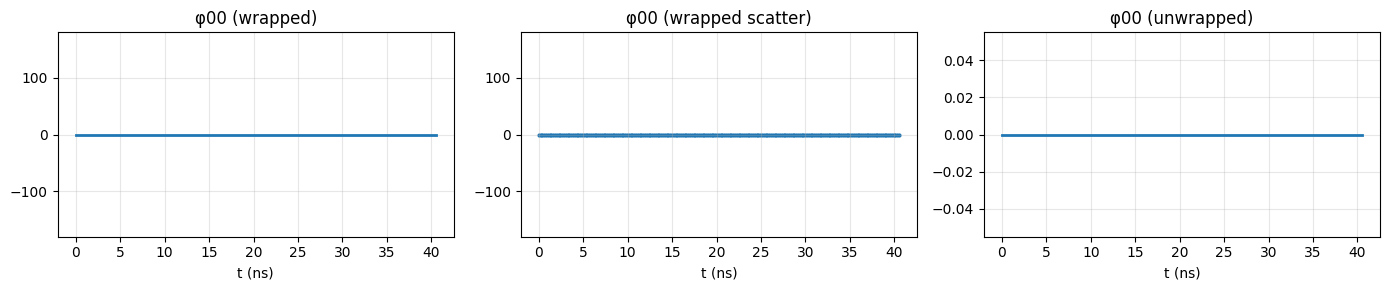

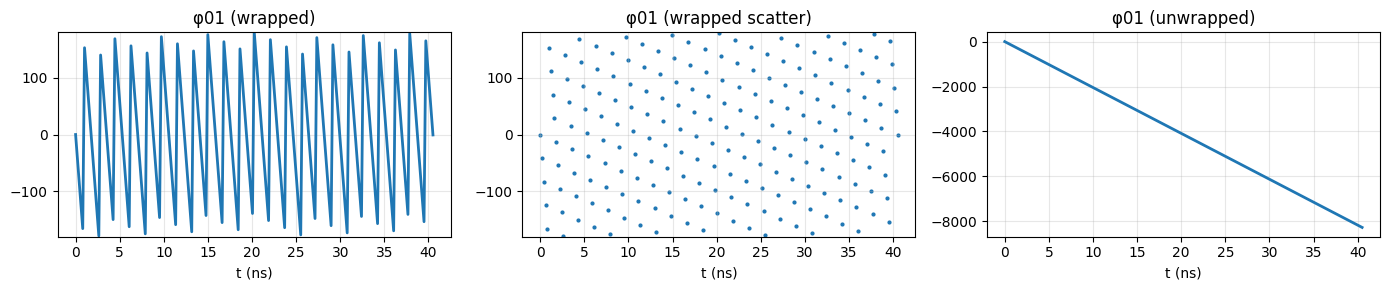

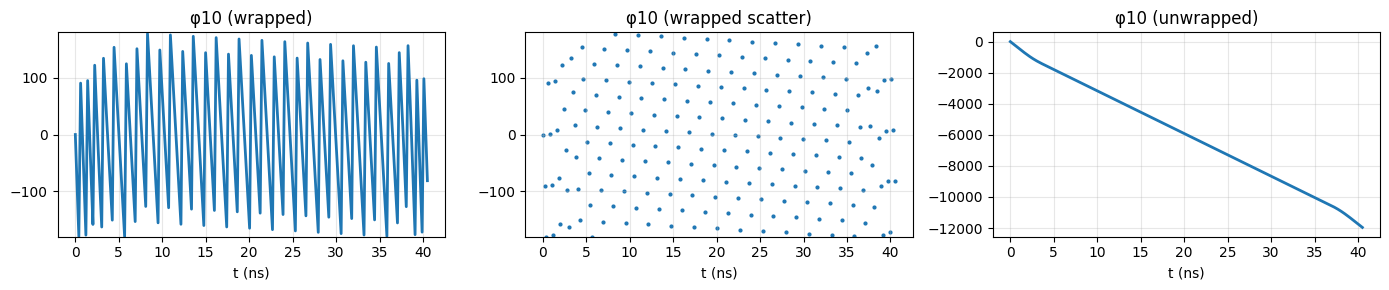

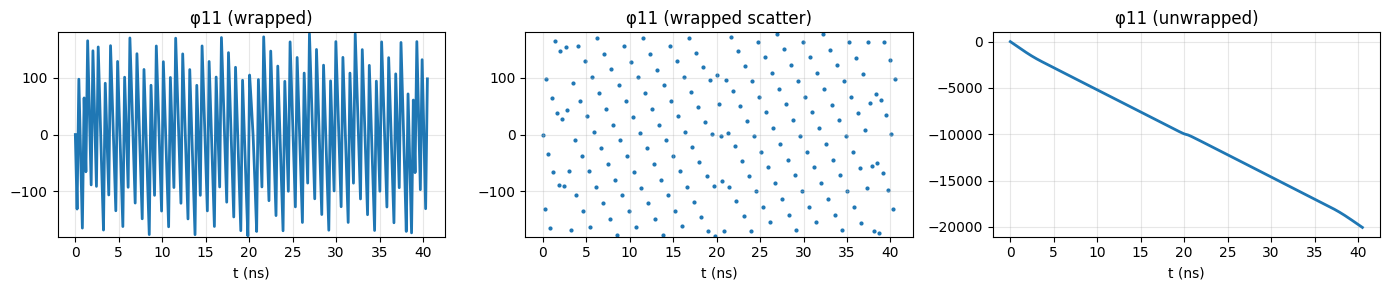

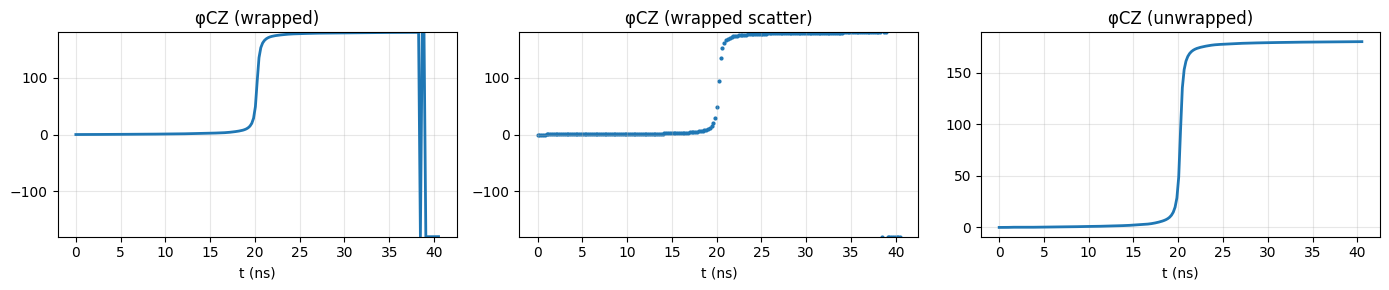


final phases, wrapped
phi00_final = 0.0 deg
phi01_final = -0.7360453149044588 deg
phi10_final = -81.35117417261851 deg
phi11_final = 98.06363997183115 deg
phiCZ_final = -179.84914054064586 deg

final phases, unwrapped
phi00_final_unw = 0.0 deg
phi01_final_unw = -8280.736045314909 deg
phi10_final_unw = -11961.351174172627 deg
phi11_final_unw = -20061.93636002816 deg
phiCZ_final_unw = 180.15085945935414 deg


In [ ]:
def wrap_deg(x):
    return (x + 180) % 360 - 180

def wrapped_deg_from_u(u):
    return wrap_deg(np.degrees(np.angle(u)))

def unwrapped_deg_from_u(u):
    return np.degrees(np.unwrap(np.angle(u)))

def plot_phase_triplet(u, title):
    w = wrapped_deg_from_u(u)
    uw = unwrapped_deg_from_u(u)

    fig, ax = plt.subplots(1, 3, figsize=(14, 3), sharex=True)

    ax[0].plot(tlist, w, lw=2)
    ax[0].set_title(title + " (wrapped)")
    ax[0].set_ylim(-180, 180)
    ax[0].grid(alpha=0.3)

    ax[1].scatter(tlist, w, s=4)
    ax[1].set_title(title + " (wrapped scatter)")
    ax[1].set_ylim(-180, 180)
    ax[1].grid(alpha=0.3)

    ax[2].plot(tlist, uw, lw=2)
    ax[2].set_title(title + " (unwrapped)")
    ax[2].grid(alpha=0.3)

    for a in ax:
        a.set_xlabel("t (ns)")

    plt.tight_layout()
    plt.show()


# individual phases
phi00_w = wrapped_deg_from_u(u00)
phi01_w = wrapped_deg_from_u(u01)
phi10_w = wrapped_deg_from_u(u10)
phi11_w = wrapped_deg_from_u(u11)

phi00_uw = unwrapped_deg_from_u(u00)
phi01_uw = unwrapped_deg_from_u(u01)
phi10_uw = unwrapped_deg_from_u(u10)
phi11_uw = unwrapped_deg_from_u(u11)


#robust CZ phase:
#phi_CZ = exp(i(theta_11 + theta_00 - theta_01 - theta_10))

cz_complex = (u11 * u00) * np.conj(u10 * u01)
phiCZ_w = wrap_deg(np.degrees(np.angle(cz_complex)))
phiCZ_uw = np.degrees(np.unwrap(np.angle(cz_complex))) #unwrapped in radians -> degrees


# plots
plot_phase_triplet(u00, "φ00")
plot_phase_triplet(u01, "φ01")
plot_phase_triplet(u10, "φ10")
plot_phase_triplet(u11, "φ11")

# CZ plots
fig, ax = plt.subplots(1, 3, figsize=(14, 3), sharex=True)

ax[0].plot(tlist, phiCZ_w, lw=2)
ax[0].set_title("φCZ (wrapped)")
ax[0].set_ylim(-180, 180)
ax[0].grid(alpha=0.3)

ax[1].scatter(tlist, phiCZ_w, s=4)
ax[1].set_title("φCZ (wrapped scatter)")
ax[1].set_ylim(-180, 180)
ax[1].grid(alpha=0.3)

ax[2].plot(tlist, phiCZ_uw, lw=2)
ax[2].set_title("φCZ (unwrapped)")
ax[2].grid(alpha=0.3)

for a in ax:
    a.set_xlabel("t (ns)")

plt.tight_layout()
plt.show()

# prints
print("\nfinal phases, wrapped")
print("phi00_final =", float(phi00_w[-1]), "deg")
print("phi01_final =", float(phi01_w[-1]), "deg")
print("phi10_final =", float(phi10_w[-1]), "deg")
print("phi11_final =", float(phi11_w[-1]), "deg")
print("phiCZ_final =", float(phiCZ_w[-1]), "deg")

print("\nfinal phases, unwrapped")
print("phi00_final_unw =", float(phi00_uw[-1]), "deg")
print("phi01_final_unw =", float(phi01_uw[-1]), "deg")
print("phi10_final_unw =", float(phi10_uw[-1]), "deg")
print("phi11_final_unw =", float(phi11_uw[-1]), "deg")
print("phiCZ_final_unw =", float(phiCZ_uw[-1]), "deg")


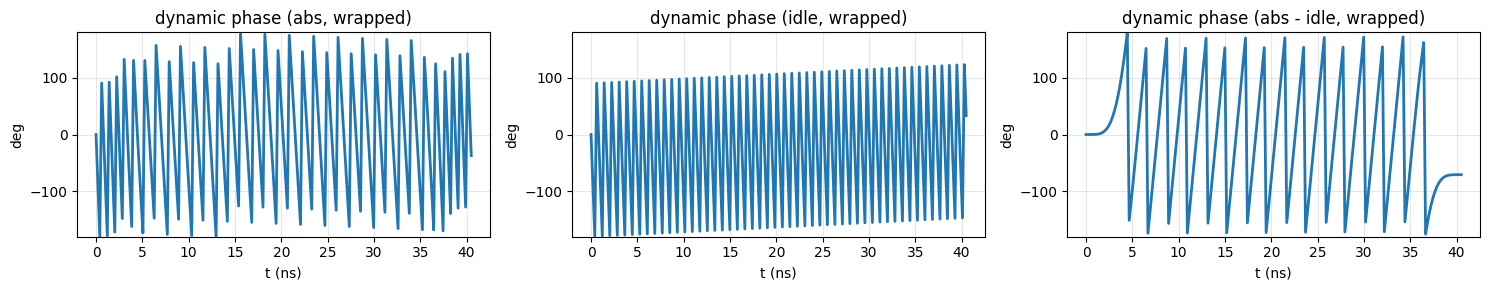

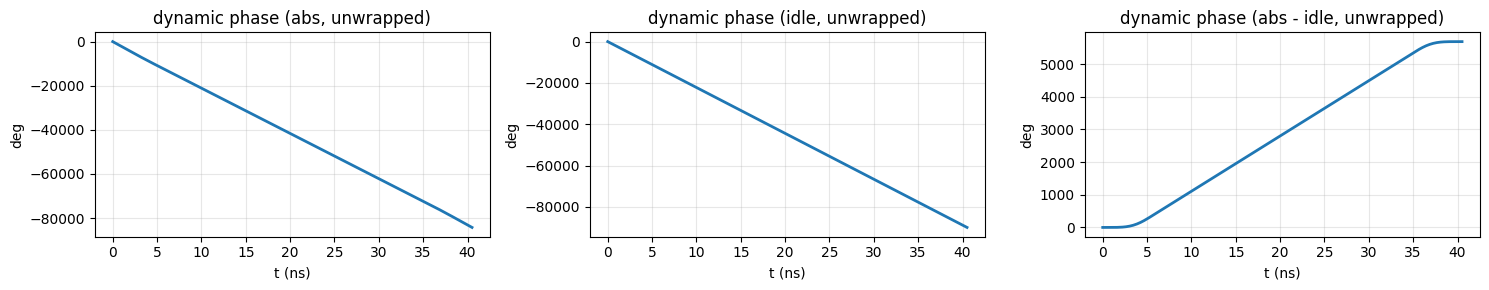


dynamic phases:
w_idle = 6.169025696282958 GHz
dyn_phase_abs_final_wrapped = -37.30539120986941 deg
dyn_phase_idle_final_wrapped = 33.39685568783898 deg
dyn_phase_rel_final_wrapped = -70.70224689770839 deg
dyn_phase_rel_final_unwrapped = 5689.297753102292 deg


In [ ]:
def wrap_deg(x):
    return (x + 180) % 360 - 180

dt = float(tlist[1] - tlist[0])

#w1(t) along the pulse (GHz)
w1_t = np.array([float(w1_interp(ph)) for ph in phi_wave])

#dynamic phase: -360 * integral( w1(t) dt (deg))
dyn_phase_abs_unw = -360.0 * np.cumsum(0.5*(w1_t[1:] + w1_t[:-1])) * dt
dyn_phase_abs_unw = np.insert(dyn_phase_abs_unw, 0, 0.0)
dyn_phase_abs_w = wrap_deg(dyn_phase_abs_unw)

#idle reference: constant w1 at phi_idle
w_idle = float(w1_interp(phi_idle))
dyn_phase_idle_unw = -360.0 * (w_idle * tlist) #since tlist in ns, w in GHz
dyn_phase_idle_w = wrap_deg(dyn_phase_idle_unw)

#relative dynamic phase (subtract idle)
dyn_phase_rel_unw = dyn_phase_abs_unw - dyn_phase_idle_unw
dyn_phase_rel_w = wrap_deg(dyn_phase_rel_unw)


# plots: wrapped
fig, ax = plt.subplots(1, 3, figsize=(15, 3), sharex=True)

ax[0].plot(tlist, dyn_phase_abs_w, lw=2)
ax[0].set_title("dynamic phase (abs, wrapped)")
ax[0].set_ylim(-180, 180)
ax[0].grid(alpha=0.3)

ax[1].plot(tlist, dyn_phase_idle_w, lw=2)
ax[1].set_title("dynamic phase (idle, wrapped)")
ax[1].set_ylim(-180, 180)
ax[1].grid(alpha=0.3)

ax[2].plot(tlist, dyn_phase_rel_w, lw=2)
ax[2].set_title("dynamic phase (abs - idle, wrapped)")
ax[2].set_ylim(-180, 180)
ax[2].grid(alpha=0.3)

for a in ax:
    a.set_xlabel("t (ns)")
    a.set_ylabel("deg")

plt.tight_layout()
plt.show()


# plots: unwrapped
fig, ax = plt.subplots(1, 3, figsize=(15, 3), sharex=True)

ax[0].plot(tlist, dyn_phase_abs_unw, lw=2)
ax[0].set_title("dynamic phase (abs, unwrapped)")
ax[0].grid(alpha=0.3)

ax[1].plot(tlist, dyn_phase_idle_unw, lw=2)
ax[1].set_title("dynamic phase (idle, unwrapped)")
ax[1].grid(alpha=0.3)

ax[2].plot(tlist, dyn_phase_rel_unw, lw=2)
ax[2].set_title("dynamic phase (abs - idle, unwrapped)")
ax[2].grid(alpha=0.3)

for a in ax:
    a.set_xlabel("t (ns)")
    a.set_ylabel("deg")

plt.tight_layout()
plt.show()

print("\ndynamic phases:")
print("w_idle =", w_idle, "GHz")
print("dyn_phase_abs_final_wrapped =", float(dyn_phase_abs_w[-1]), "deg")
print("dyn_phase_idle_final_wrapped =", float(dyn_phase_idle_w[-1]), "deg")
print("dyn_phase_rel_final_wrapped =", float(dyn_phase_rel_w[-1]), "deg")
print("dyn_phase_rel_final_unwrapped =", float(dyn_phase_rel_unw[-1]), "deg")


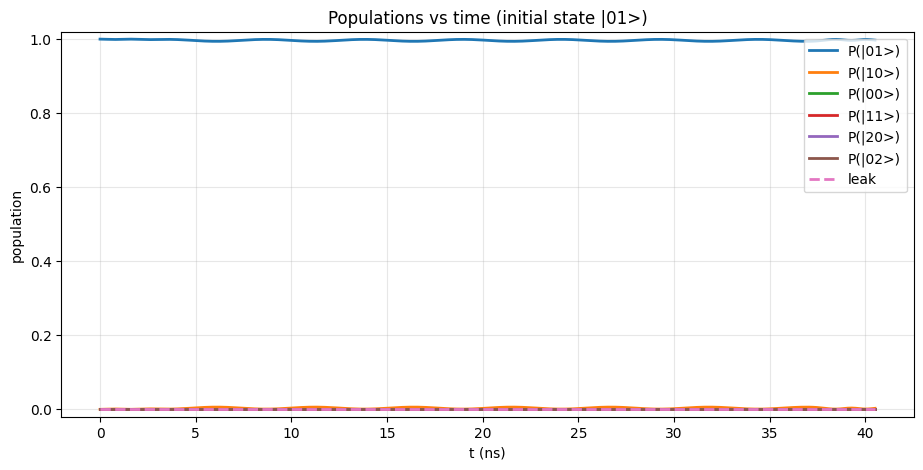


Final populations (initial |01> )
P00_final = 0.0
P01_final = 0.9973133583699816
P10_final = 0.0026866416300180785
P11_final = 0.0
P20_final = 0.0
P02_final = 0.0
Leak_final = 3.3306690738754696e-16


In [ ]:
#populations starting from a chosen input state like |01>

#choose input: res01/ket01 or res10/ket10
res_in = res01
label_in = "|01>"

#basis kets (need N defined)
ket20 = qt.tensor(qt.basis(N, 2), qt.basis(N, 0))
ket02 = qt.tensor(qt.basis(N, 0), qt.basis(N, 2))

pop00 = np.array([abs(ket00.overlap(st))**2 for st in res_in.states])
pop01 = np.array([abs(ket01.overlap(st))**2 for st in res_in.states])
pop10 = np.array([abs(ket10.overlap(st))**2 for st in res_in.states])
pop11 = np.array([abs(ket11.overlap(st))**2 for st in res_in.states])
pop20 = np.array([abs(ket20.overlap(st))**2 for st in res_in.states])
pop02 = np.array([abs(ket02.overlap(st))**2 for st in res_in.states])

leak = 1.0 - (pop00 + pop01 + pop10 + pop11 + pop20 + pop02)

plt.figure(figsize=(11,5))
plt.plot(tlist, pop01, lw=2, label="P(|01>)")
plt.plot(tlist, pop10, lw=2, label="P(|10>)")
plt.plot(tlist, pop00, lw=2, label="P(|00>)")
plt.plot(tlist, pop11, lw=2, label="P(|11>)")
plt.plot(tlist, pop20, lw=2, label="P(|20>)")
plt.plot(tlist, pop02, lw=2, label="P(|02>)")
plt.plot(tlist, leak, "--", lw=2, label="leak")
plt.xlabel("t (ns)")
plt.ylabel("population")
plt.grid(alpha=0.3)
plt.legend(loc="upper right")
plt.title(f"Populations vs time (initial state {label_in})")
plt.ylim(-0.02, 1.02)
plt.show()

print("\nFinal populations (initial", label_in,")")
print("P00_final =", float(pop00[-1]))
print("P01_final =", float(pop01[-1]))
print("P10_final =", float(pop10[-1]))
print("P11_final =", float(pop11[-1]))
print("P20_final =", float(pop20[-1]))
print("P02_final =", float(pop02[-1]))
print("Leak_final =", float(leak[-1]))


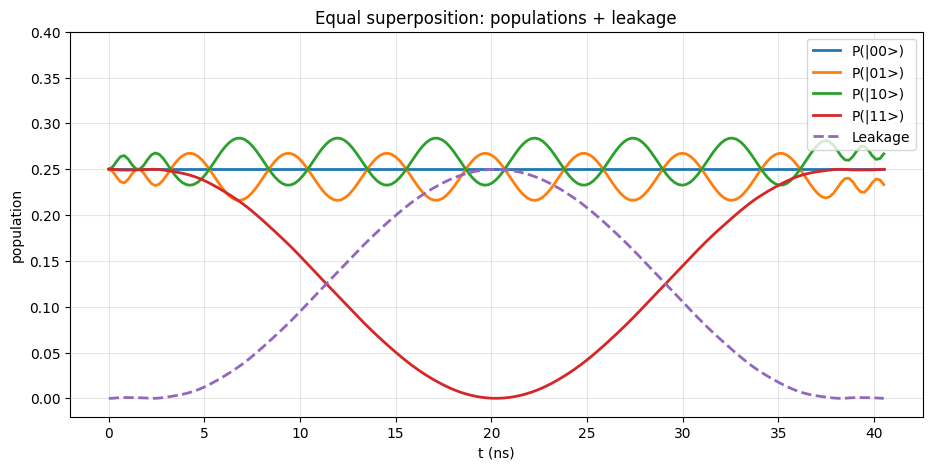


Final values:
P_comp_final = 0.9999813215736484
Leak_final   = 1.8678426351614874e-05
P00_final = 0.25000085240075626
P01_final = 0.2332582031530164
P10_final = 0.2667433973882942
P11_final = 0.2499788686315815


In [ ]:
#equal superposition (|00>+|01>+|10>+|11>)/2

psi_eq = (ket00 + ket01 + ket10 + ket11).unit()

#H_t needs args=args_base, and we keep solver options consistent
res_eq = qt.sesolve(H_t, psi_eq, tlist, args=args_base, options=opts)

#populations in computational basis
P00 = np.array([abs(ket00.overlap(st))**2 for st in res_eq.states])
P01 = np.array([abs(ket01.overlap(st))**2 for st in res_eq.states])
P10 = np.array([abs(ket10.overlap(st))**2 for st in res_eq.states])
P11 = np.array([abs(ket11.overlap(st))**2 for st in res_eq.states])

P_comp = P00 + P01 + P10 + P11
Leak = 1.0 - P_comp

plt.figure(figsize=(11,5))
plt.plot(tlist, P00, lw=2, label="P(|00>)")
plt.plot(tlist, P01, lw=2, label="P(|01>)")
plt.plot(tlist, P10, lw=2, label="P(|10>)")
plt.plot(tlist, P11, lw=2, label="P(|11>)")
plt.plot(tlist, Leak, "--", lw=2, label="Leakage")
plt.xlabel("t (ns)")
plt.ylabel("population")
plt.grid(alpha=0.3)
plt.legend(loc="upper right")
plt.title("Equal superposition: populations + leakage")
plt.ylim(-0.02, 0.4)
plt.show()

print("\nFinal values:")
print("P_comp_final =", float(P_comp[-1]))
print("Leak_final   =", float(Leak[-1]))
print("P00_final =", float(P00[-1]))
print("P01_final =", float(P01[-1]))
print("P10_final =", float(P10[-1]))
print("P11_final =", float(P11[-1]))


In [ ]:
#we extract comp. subspace unitary U_CZ (4x4) from basis runs
#columns = outputs for inputs |00>,|01>,|10>,|11>

basis = [ket00, ket01, ket10, ket11]
res_list = [res00, res01, res10, res11]

U_CZ = np.zeros((4,4), dtype=complex)
for j, res in enumerate(res_list):
    psiT = res.states[-1]
    for i, bi in enumerate(basis):
        U_CZ[i, j] = bi.overlap(psiT)

#print(U_CZ)
print("\n|U_CZ|^2:")
print(np.round(np.abs(U_CZ)**2, 4))

print("\nDiag phases of U_CZ (deg):",
      np.round(np.degrees(np.angle(np.diag(U_CZ))), 3))


|U_CZ|^2:
[[1.     0.     0.     0.    ]
 [0.     0.9973 0.0027 0.    ]
 [0.     0.0027 0.9973 0.    ]
 [0.     0.     0.     0.9999]]

Diag phases of U_CZ (deg): [  0.     -0.736 -81.351  98.064]


In [ ]:
#we build CNOT from U_CZ by wrapping with Hadamards
#target qubit q2

H = (1/np.sqrt(2))*np.array([[1, 1],
                             [1,-1]], dtype=complex)
I2 = np.eye(2, dtype=complex)

# target = q2 : I ⊗ H
H_target_q2 = np.kron(I2, H)

# target = q1 : H ⊗ I
#H_target_q1 = np.kron(H, I2)

Hwrap = H_target_q2

U_CNOT = Hwrap @ U_CZ @ Hwrap

#ideal cnot withtarget q2 in |00,01,10,11| ordering
U_CNOT_ideal = np.array([
    [1,0,0,0],
    [0,1,0,0],
    [0,0,0,1],
    [0,0,1,0]
], dtype=complex)

#compare up to global phase
phi_opt = np.angle(np.trace(U_CNOT_ideal.conj().T @ U_CNOT))
U_CNOT_phased = U_CNOT * np.exp(-1j*phi_opt)
F_proxy = abs(np.trace(U_CNOT_ideal.conj().T @ U_CNOT_phased))**2 / 16

print("\nCNOT check target q2:")
print("real/ideal (|Tr|^2)/16 =", float(F_proxy))

labels = ["00","01","10","11"]
print("\nTruth table probs:")
for j in range(4):
    probs = np.abs(U_CNOT[:, j])**2
    print("input |{}> -> ".format(labels[j]) +
          ", ".join([f"P({labels[i]})={probs[i]:.4f}" for i in range(4)]))



CNOT check target q2:
real/ideal (|Tr|^2)/16 = 0.575031949814057

Truth table probs:
input |00> -> P(00)=0.9986, P(01)=0.0000, P(10)=0.0007, P(11)=0.0007
input |01> -> P(00)=0.0000, P(01)=0.9986, P(10)=0.0007, P(11)=0.0007
input |10> -> P(00)=0.0007, P(01)=0.0007, P(10)=0.0000, P(11)=0.9986
input |11> -> P(00)=0.0007, P(01)=0.0007, P(10)=0.9986, P(11)=0.0000


In [ ]:
#virtual Z (single qubit) phase corrections from diagonal phases

def wrap_deg_signed(x):
    return (x + 180.0) % 360.0 - 180.0

theta = np.angle(np.diag(U_CZ))
theta00, theta01, theta10, theta11 = [float(x) for x in theta]

Z_q1_deg = wrap_deg_signed(np.degrees(theta10 - theta00)) #phase to remove on q1
Z_q2_deg = wrap_deg_signed(np.degrees(theta01 - theta00)) #phase to remove on q2

phiCZ_deg = wrap_deg_signed(np.degrees(theta11 + theta00 - theta10 - theta01))
phiCZ_abs = abs(phiCZ_deg)

print(f"Z correction on q1 = {Z_q1_deg:.3f} deg")
print(f"Z correction on q2  = {Z_q2_deg:.3f} deg")
print(f"|phi_CZ| = {phiCZ_abs:.3f} deg")


Z correction on q1 = -81.351 deg
Z correction on q2  = -0.736 deg
|phi_CZ| = 179.849 deg


In [ ]:
'''
we need to canonicalize CZ:
remove local (single-qubit) Z phases
(so we apply virtual Z gates)
so that  U becomes diag(1,1,1,e^{i*phi_CZ})
'''

def closest_unitary(M):
    U, s, Vh = np.linalg.svd(M)
    return U @ Vh

U_CZ_unitary = closest_unitary(U_CZ)

#Extract diagonal phases
d = np.diag(U_CZ_unitary)
theta = np.angle(d) #[theta00, theta01, theta10, theta11]

theta00, theta01, theta10, theta11 = [float(x) for x in theta]

'''
solve for local phases:
we want to apply left-multiplication by diag(exp(-i*chi_ij)) where
chi_00 = 0
chi_01 = b
chi_10 = a
chi_11 = a+b
'''

# choose a = theta10 - theta00, b = theta01 - theta00
a = theta10 - theta00
b = theta01 - theta00

chi = np.array([0.0, b, a, a+b], dtype=float)

L = np.diag(np.exp(-1j*chi)) #local Z corrections (acts on output)



U_can = L @ U_CZ_unitary
#also remove global phase so that (00,00) is 1
U_can = U_can * np.exp(-1j*np.angle(U_can[0,0]))

print("\n|U_can|^2:")
print(np.round(np.abs(U_can)**2, 4))

print("\nDiag phases of U_can (deg):",
      np.round(np.degrees(np.angle(np.diag(U_can))), 3))



|U_can|^2:
[[1.     0.     0.     0.    ]
 [0.     0.9973 0.0027 0.    ]
 [0.     0.0027 0.9973 0.    ]
 [0.     0.     0.     1.    ]]

Diag phases of U_can (deg): [   0.       0.       0.    -179.849]


pulse duration: 16.0 ns
q2 anharmonicity = -203.4 MHz
Standard (lambda=0): fid=0.999614
Optimal DRAG (lambda=0.950): fid=0.999995

|H_std|^2:
[[0.5193 0.4807]
 [0.4807 0.5193]]

|H_drag|^2:
[[0.4998 0.5002]
 [0.5002 0.4998]]

Truth table CNOT (standard pulse H)
in |00> -> P(00)=0.9987, P(01)=0.0000, P(10)=0.0007, P(11)=0.0006
in |01> -> P(00)=0.0000, P(01)=0.9986, P(10)=0.0007, P(11)=0.0007
in |10> -> P(00)=0.0007, P(01)=0.0007, P(10)=0.0015, P(11)=0.9971
in |11> -> P(00)=0.0006, P(01)=0.0007, P(10)=0.9971, P(11)=0.0016

Truth table CNOT (DRAG pulse H)
in |00> -> P(00)=0.9986, P(01)=0.0000, P(10)=0.0007, P(11)=0.0007
in |01> -> P(00)=0.0000, P(01)=0.9986, P(10)=0.0007, P(11)=0.0007
in |10> -> P(00)=0.0007, P(01)=0.0007, P(10)=0.0000, P(11)=0.9986
in |11> -> P(00)=0.0007, P(01)=0.0007, P(10)=0.9986, P(11)=0.0000


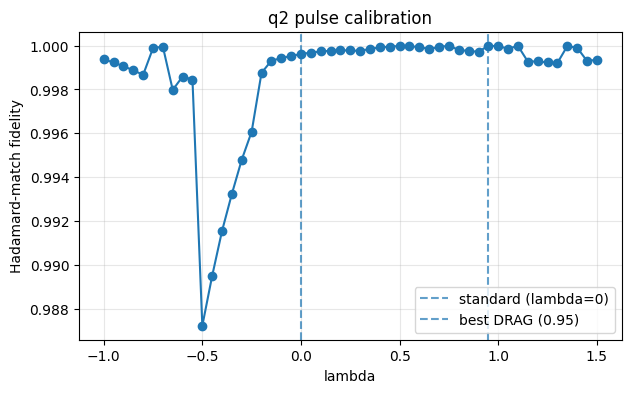

In [ ]:
#now DRAG based realistic Hadamard on q2
# CNOT = (I ⊗ H_q2) U_can (I ⊗ H_q2)

dim1 = 3  # 3 level model for q2
T_pulse_1q = 16.0  # ns
print("pulse duration:", T_pulse_1q, "ns")
n_steps_1q = 1000
detuning_1q = 0.0 * 2*np.pi # rad/ns (on-resonance)
phi_drive = np.pi/2 # Y-type rotation

# q2 anharmonicity in rad/ns
alpha_q2_rad = 2*np.pi * float(alpha2)
print(f"q2 anharmonicity = {alpha_q2_rad/(2*np.pi)*1000:.1f} MHz")

a_1q = qt.destroy(dim1)
adag_1q = a_1q.dag()

#rotating frame Duffing drift (no detuning term - on resonance)
H_drift_1q = (alpha_q2_rad / 2.0) * adag_1q * adag_1q * a_1q * a_1q


def hann_shape(t, T):
    if (t < 0) or (t > T):
        return 0.0
    return 0.5 * (1.0 - np.cos(2.0 * np.pi * t / T))

def deriv_hann(t, T):
    if (t < 0) or (t > T):
        return 0.0
    return 0.5 * (2.0 * np.pi / T) * np.sin(2.0 * np.pi * t / T)


def make_coeffs_1q(amp, lambda_val):
    """
    Ox = amp * s(t)
    Oy = amp * lambda * ds/dt / alpha (DRAG correction)
    complex drive coefficient in rotating frame
    """
    def coeff(t, args):
        if t > T_pulse_1q:
            return 0.0
        Ox = amp * hann_shape(t, T_pulse_1q)
        ds_dt = deriv_hann(t, T_pulse_1q)
        Oy = amp * lambda_val * ds_dt / alpha_q2_rad
        envelope = -0.5 * (Ox - 1j * Oy)
        phase = np.exp(1j * (detuning_1q * t + phi_drive))
        return envelope * phase

    def coeff_conj(t, args):
        return np.conj(coeff(t, args))

    return coeff, coeff_conj


# ideal Hadamard for reference
H_ideal = (1/np.sqrt(2)) * np.array([[1,  1],
                                     [1, -1]], dtype=complex)

def gate_overlap_2x2(U, Uideal):
    phi_opt = np.angle(np.trace(Uideal.conj().T @ U))
    U_phased = U * np.exp(-1j * phi_opt)
    return float(np.abs(np.trace(Uideal.conj().T @ U_phased))**2 / 4.0)

def closest_unitary_2x2(M):
    U, s, Vh = np.linalg.svd(M)
    return U @ Vh

def best_hadamard_from_U2(U2):
    """
    search over pre/post virtual-Z angles to find the best Hadamard match
    H_eff = Rz_post @ U2 @ Rz_pre
    Returns (fid, gamma_pre, gamma_post, H_eff)
    """
    gamma_grid = np.linspace(-np.pi, np.pi, 181)
    best = None
    for gamma_pre in gamma_grid:
        Rz_pre = np.array([[np.exp(-1j*gamma_pre/2), 0],
                           [0, np.exp(+1j*gamma_pre/2)]], dtype=complex)
        U_pre = U2 @ Rz_pre
        for gamma_post in gamma_grid:
            Rz_post = np.array([[np.exp(-1j*gamma_post/2), 0],
                                [0, np.exp(+1j*gamma_post/2)]], dtype=complex)
            H_eff = Rz_post @ U_pre
            fid = gate_overlap_2x2(H_eff, H_ideal)
            if not np.isfinite(fid):
                continue
            if (best is None) or (fid > best[0]):
                best = (fid, gamma_pre, gamma_post, H_eff)
    return best

def get_1q_unitary_from_pulse(amp, lambda_val):
    cp, cm = make_coeffs_1q(amp, lambda_val)
    H_1q = [H_drift_1q, [adag_1q, cp], [a_1q, cm]]
    U = qt.propagator(H_1q, T_pulse_1q, c_ops=[], args={},
                      options={"rtol": 1e-6, "atol": 1e-8})
    return U.full() # 3x3

def get_hadamard_score(amp, lambda_val):
    U3 = get_1q_unitary_from_pulse(amp, lambda_val)
    U2 = U3[:2, :2]
    U2_unitary = closest_unitary_2x2(U2)
    out = best_hadamard_from_U2(U2_unitary)
    if out is None:
        return -np.inf, 0.0, 0.0, 0.0, U3, U2_unitary, np.eye(2, dtype=complex)
    fidH, gamma_pre_best, gamma_post_best, H_eff = out

    # leakage penalty from computational columns
    leak0 = 1.0 - np.sum(np.abs(U3[:2, 0])**2)
    leak1 = 1.0 - np.sum(np.abs(U3[:2, 1])**2)
    leak_penalty = 0.5 * (max(0.0, leak0) + max(0.0, leak1))
    score = fidH - 5.0 * leak_penalty
    return score, float(fidH), gamma_pre_best, gamma_post_best, U3, U2_unitary, H_eff

def optimize_amp_for_lambda(lambda_val):
    res = minimize_scalar(
        lambda x: -get_hadamard_score(x, lambda_val)[0],
        bounds=(0.01, 5.0),
        method="bounded"
    )
    amp_best = float(res.x)
    score_best, fidH_best, gpre, gpost, U3_best, U2_best, H_eff_best = get_hadamard_score(amp_best, lambda_val)
    return amp_best, score_best, fidH_best, gpre, gpost, U3_best, U2_best, H_eff_best


# sweep lambda
lambdas_1q = np.linspace(-1.0, 1.5, 51)
scores_1q = []; fidsH_1q = []; amps_1q = []
gammas_pre_1q = []; gammas_post_1q = []
U3_list = []; U2_list = []; Heff_list = []

for lam in lambdas_1q:
    aopt, sopt, fHopt, gpre, gpost, U3opt, U2opt, Heffopt = optimize_amp_for_lambda(lam)
    amps_1q.append(aopt); scores_1q.append(sopt); fidsH_1q.append(fHopt)
    gammas_pre_1q.append(gpre); gammas_post_1q.append(gpost)
    U3_list.append(U3opt); U2_list.append(U2opt); Heff_list.append(Heffopt)


best_idx = int(np.argmax(fidsH_1q))
best_lambda_1q = float(lambdas_1q[best_idx])
best_fid_1q = float(fidsH_1q[best_idx])
best_gamma_pre_1q = float(gammas_pre_1q[best_idx])
best_gamma_post_1q = float(gammas_post_1q[best_idx])

std_idx = int(np.argmin(np.abs(lambdas_1q - 0.0)))
std_fid_1q = float(fidsH_1q[std_idx])
std_gamma_pre_1q = float(gammas_pre_1q[std_idx])
std_gamma_post_1q = float(gammas_post_1q[std_idx])

print(f"Standard (lambda=0): fid={std_fid_1q:.6f}")
print(f"Optimal DRAG (lambda={best_lambda_1q:.3f}): fid={best_fid_1q:.6f}")


U_std_3 = U3_list[std_idx]
U_drag_3 = U3_list[best_idx]
H_std_eff = Heff_list[std_idx]
H_drag_eff = Heff_list[best_idx]

print("\n|H_std|^2:")
print(np.round(np.abs(H_std_eff)**2, 4))
print("\n|H_drag|^2:")
print(np.round(np.abs(H_drag_eff)**2, 4))


# build CNOTs using canonical CZ (U_can)
I2 = np.eye(2, dtype=complex)
Hwrap_ideal = np.kron(I2, H_ideal)
Hwrap_std   = np.kron(I2, H_std_eff)
Hwrap_drag  = np.kron(I2, H_drag_eff)

U_CNOT_ideal = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]], dtype=complex)

U_CNOT_from_idealH = Hwrap_ideal @ U_can @ Hwrap_ideal
U_CNOT_from_stdH   = Hwrap_std   @ U_can @ Hwrap_std
U_CNOT_from_dragH  = Hwrap_drag  @ U_can @ Hwrap_drag


labels = ["00","01","10","11"]
def print_truth_table(U, title):
    print(f"\n{title}")
    for j in range(4):
        probs = np.abs(U[:, j])**2
        print("in |{}> -> ".format(labels[j]) +
              ", ".join([f"P({labels[i]})={probs[i]:.4f}" for i in range(4)]))

print_truth_table(U_CNOT_from_stdH,  "Truth table CNOT (standard pulse H)")
print_truth_table(U_CNOT_from_dragH, "Truth table CNOT (DRAG pulse H)")


# lambda sweep plot
plt.figure(figsize=(7,4))
plt.plot(lambdas_1q, fidsH_1q, "o-")
plt.axvline(0.0, ls="--", alpha=0.7, label="standard (lambda=0)")
plt.axvline(best_lambda_1q, ls="--", alpha=0.7, label=f"best DRAG ({best_lambda_1q:.2f})")
plt.xlabel("lambda")
plt.ylabel("Hadamard-match fidelity")
plt.title("q2 pulse calibration")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
def avg_truth_success(U):
    #columns input, rows output in |00,01,10,11|
    targets = [0, 1, 3, 2] #outputs for inputs 00,01,10,11
    return float(np.mean([np.abs(U[targets[j], j])**2 for j in range(4)]))

print("\nAverage truth table success:")
print("Standard pulse H:", avg_truth_success(U_CNOT_from_stdH))
print("DRAG pulse H    :", avg_truth_success(U_CNOT_from_dragH))


Average truth table success:
Standard pulse H: 0.9978778088429585
DRAG pulse H    : 0.9986410136226402


In [ ]:
#average gate fidelity of CNOT

def avg_gate_fidelity(U_actual, U_ideal):
    """
    F_avg = (|Tr(U_ideal† U_actual)|² + d) / (d(d+1))
    truth table only measures population in the correct output bin (ignoring phase),
    while F_avg rewards coherent errors
    amplitude leaks between states
    """
    d = U_ideal.shape[0]
    M = U_ideal.conj().T @ U_actual
    return (abs(np.trace(M))**2 + d) / (d * (d + 1))


#build ideal CZ and ideal CNOT
U_CZ_ideal = np.diag([1.0, 1.0, 1.0, -1.0]).astype(complex)

I2 = np.eye(2, dtype=complex)
H_mat = (1/np.sqrt(2)) * np.array([[1, 1],[1,-1]], dtype=complex)
U_CNOT_ideal = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]], dtype=complex)


#we use the canonicalized CZ (U_can) because single qubit phases already removed
F_CZ   = avg_gate_fidelity(U_can, U_CZ_ideal)
print(f"Average gate fidelity of CZ (after virtual-Z):  {F_CZ:.6f}")
print(f"Infidelity = {(1-F_CZ)*100:.4f}%")

#for CNOT we use U_CNOT_from_stdH and U_CNOT_from_dragH
F_CNOT_std  = avg_gate_fidelity(U_CNOT_from_stdH,  U_CNOT_ideal)
F_CNOT_drag = avg_gate_fidelity(U_CNOT_from_dragH, U_CNOT_ideal)
print(f"\nAverage gate fidelity of CNOT (standard H): {F_CNOT_std:.6f}")
print(f"Average gate fidelity of CNOT (DRAG H): {F_CNOT_drag:.6f}")
print(f"\nTruth-table success (standard H): {avg_truth_success(U_CNOT_from_stdH):.6f}")
print(f"Truth-table success (DRAG H): {avg_truth_success(U_CNOT_from_dragH):.6f}")

Average gate fidelity of CZ (after virtual-Z):  0.998924
Infidelity = 0.1076%

Average gate fidelity of CNOT (standard H): 0.998289
Average gate fidelity of CNOT (DRAG H): 0.998908

Truth-table success (standard H): 0.997878
Truth-table success (DRAG H): 0.998641
